# Part 1 (i): Tabular data: Hotel Booking Demand
**CMPE 255: EDA, data preparation and AutoML**

| | |
|---|---|
| **Dataset** | [Hotel booking demand (Kaggle)](https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand): 119,390 bookings × 32 columns from two hotels in Portugal (a city hotel and a resort hotel), arrivals Jul 2015 to Aug 2017 |
| **Why this dataset** | Mixed data types (numeric, categorical, dates, ISO country codes, ID codes), real quality problems (27% duplicate rows, sparse columns, impossible values, target leakage) and a clear business target |
| **Prediction task** | Binary classification: will a booking be **canceled** (`is_canceled`)? |
| **AutoML** | [AutoViML](https://github.com/AutoViML/Auto_ViML) (plus AutoViz for automated EDA) |

### Pipeline
```
Load → Overview → Data-quality audit → EDA & visualisation → Auto-EDA (AutoViz)
     → Leakage scan & duplicate analysis → Cleaning (dedupe, leakage, impossible rows, types)
     → Chronological train/test split → Sensitivity checks (split, duplicates, leaky features)
     → Imputation (fit on train only) → Feature engineering
     → Anomaly detection & removal → Clustering (guest segments)
     → Feature selection → AutoViML models + baselines → Evaluation → Conclusions
```
Every step that *learns* something from the data (imputation values, scalers, anomaly detector, clusters, feature selection) is **fit on the training split only** and then applied to the test split, so the test score stays honest.

### How this notebook was built
> ✍️ *TODO (you): state honestly how you used a coding agent, e.g. "Scaffolded with Claude Code; I reviewed every step, ran it, and wrote the observations and conclusions myself."*

## 0. Setup
AutoViML 0.2.2 only works with specific library versions (see `part1/requirements.txt`). On **Colab** the next cell installs them and **restarts the runtime once**. When it reconnects, choose *Runtime → Run all* again. Locally, `pip install -r part1/requirements.txt` first.

In [1]:
import os, sys

IN_COLAB = "google.colab" in sys.modules


def _env_ready():
    try:
        import importlib.metadata as md
        return (md.version("autoviml") == "0.2.2"
                and md.version("scikit-learn") == "1.3.2"
                and md.version("numpy").startswith("1."))
    except Exception:
        return False


if IN_COLAB and not _env_ready():
    %pip install -q autoviml==0.2.2 autoviz==0.1.905 scikit-learn==1.3.2 imbalanced-learn==0.12.4 "numpy<2" scipy==1.11.4 "pandas<2.3" "setuptools<81"
    print("Installed pinned packages -> restarting runtime. Afterwards: Runtime -> Run all.")
    os.kill(os.getpid(), 9)

In [2]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, RobustScaler, OrdinalEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import IsolationForest
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, accuracy_score, balanced_accuracy_score, precision_score,
                             recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay)
from sklearn.feature_selection import mutual_info_classif
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 4.5)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# ---- run configuration ----
TARGET = "is_canceled"
SAMPLE_FRAC = 1.0      # set e.g. 0.2 for a quick dry run
RUN_AUTOVIZ = True     # automated EDA (adds ~1 min)

In [3]:
DATA_FILE = "hotel_bookings.csv"
REPO_RAW = "https://raw.githubusercontent.com/anita-agasaveeran/CMPE255_Exploratory_Data_Analysis/main/data/"


def load_csv(name):
    """Load from the repo's data/ folder when run locally, otherwise from GitHub (e.g. on Colab)."""
    for base in [Path("../../data"), Path("../data"), Path("data"), Path("/content/data")]:
        if (base / name).exists():
            print(f"Loading local file {base / name}")
            return pd.read_csv(base / name)
    print(f"Loading {REPO_RAW + name}")
    return pd.read_csv(REPO_RAW + name)


df_raw = load_csv(DATA_FILE)
print(df_raw.shape)
df_raw.head()

Loading local file ../../data/hotel_bookings.csv
(119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,country,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,assigned_room_type,booking_changes,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,3,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,0.0,0,BB,PRT,Direct,Direct,0,0,0,C,C,4,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Direct,Direct,0,0,0,A,C,0,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,0.0,0,BB,GBR,Corporate,Corporate,0,0,0,A,A,0,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,0.0,0,BB,GBR,Online TA,TA/TO,0,0,0,A,A,0,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


## 1. Data overview
First look at the schema: data types, cardinality, missingness and an example value for every column.

In [4]:
overview = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "n_unique": df_raw.nunique(),
    "n_missing": df_raw.isna().sum(),
    "pct_missing": df_raw.isna().mean().mul(100).round(2),
    "example": df_raw.iloc[0],
})
overview

,dtype,n_unique,n_missing,pct_missing,example
hotel,object,2,0,0.00,Resort Hotel
is_canceled,int64,2,0,0.00,0
lead_time,int64,479,0,0.00,342
arrival_date_year,int64,3,0,0.00,2015
arrival_date_month,object,12,0,0.00,July
arrival_date_week_number,int64,53,0,0.00,27
arrival_date_day_of_month,int64,31,0,0.00,1
stays_in_weekend_nights,int64,17,0,0.00,0
stays_in_week_nights,int64,35,0,0.00,0
adults,int64,14,0,0.00,2


In [5]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
is_canceled,119390.0,0.370416,0.482918,0.00,0.00,0.000,1.0,1.0
lead_time,119390.0,104.011416,106.863097,0.00,18.00,69.000,160.0,737.0
arrival_date_year,119390.0,2016.156554,0.707476,2015.00,2016.00,2016.000,2017.0,2017.0
arrival_date_week_number,119390.0,27.165173,13.605138,1.00,16.00,28.000,38.0,53.0
arrival_date_day_of_month,119390.0,15.798241,8.780829,1.00,8.00,16.000,23.0,31.0
stays_in_weekend_nights,119390.0,0.927599,0.998613,0.00,0.00,1.000,2.0,19.0
stays_in_week_nights,119390.0,2.500302,1.908286,0.00,1.00,2.000,3.0,50.0
adults,119390.0,1.856403,0.579261,0.00,2.00,2.000,2.0,55.0
children,119386.0,0.103890,0.398561,0.00,0.00,0.000,0.0,10.0
babies,119390.0,0.007949,0.097436,0.00,0.00,0.000,0.0,10.0


In [6]:
df_raw.describe(include="object").T

,count,unique,top,freq
hotel,119390,2,City Hotel,79330
arrival_date_month,119390,12,August,13877
meal,119390,5,BB,92310
country,118902,177,PRT,48590
market_segment,119390,8,Online TA,56477
distribution_channel,119390,5,TA/TO,97870
reserved_room_type,119390,10,A,85994
assigned_room_type,119390,12,A,74053
deposit_type,119390,3,No Deposit,104641
customer_type,119390,4,Transient,89613


**Column groups** (from the data dictionary):

| Group | Columns | Notes |
|---|---|---|
| Target | `is_canceled` | 0/1 |
| Booking timing | `lead_time`, `arrival_date_*` (year, month name, week, day) | Arrival date is split over 4 columns |
| Stay | `stays_in_weekend_nights`, `stays_in_week_nights`, `adults`, `children`, `babies`, `meal` | |
| Customer and channel | `country`, `market_segment`, `distribution_channel`, `customer_type`, `is_repeated_guest`, `previous_*` | `country` is high-cardinality (ISO-3) |
| Room and price | `reserved_room_type`, `assigned_room_type`, `adr` (average daily rate), `deposit_type` | |
| IDs stored as numbers | `agent`, `company` | Numeric dtype, but really **categorical IDs** |
| Outcome columns | `reservation_status`, `reservation_status_date` | Written **after** the outcome is known, so they are **leakage** |

## 2. Data-quality audit
### 2.1 Missing values

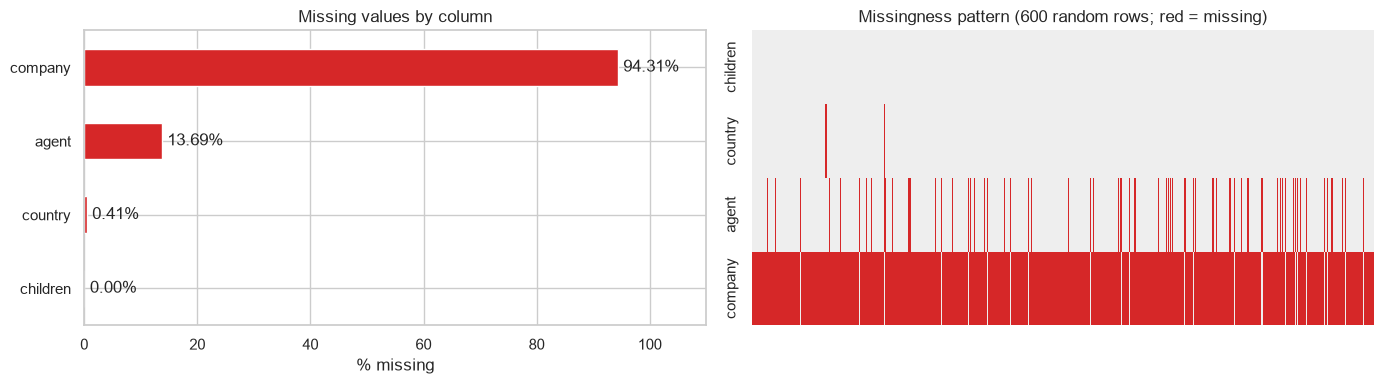

In [7]:
missing = df_raw.isna().mean().mul(100).sort_values()
missing = missing[missing > 0]
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
missing.plot.barh(ax=axes[0], color="tab:red")
for i, v in enumerate(missing):
    axes[0].text(v + 1, i, f"{v:.2f}%", va="center")
axes[0].set_xlabel("% missing")
axes[0].set_title("Missing values by column")
axes[0].set_xlim(0, 110)
sample = df_raw[missing.index].sample(600, random_state=RANDOM_STATE).isna()
sns.heatmap(sample.T, cbar=False, ax=axes[1], cmap=["#eeeeee", "tab:red"], xticklabels=False)
axes[1].set_title("Missingness pattern (600 random rows; red = missing)")
plt.tight_layout()
plt.show()

### 2.2 Duplicates, impossible values and odd categories

In [8]:
guests = df_raw["adults"] + df_raw["children"].fillna(0) + df_raw["babies"]
nights = df_raw["stays_in_weekend_nights"] + df_raw["stays_in_week_nights"]
checks = {
    "Exact duplicate rows": df_raw.duplicated().sum(),
    "adr < 0 (negative price)": (df_raw["adr"] < 0).sum(),
    "adr > 1000 (implausible price)": (df_raw["adr"] > 1000).sum(),
    "adr == 0 (complimentary / free?)": (df_raw["adr"] == 0).sum(),
    "Zero guests (adults+children+babies == 0)": (guests == 0).sum(),
    "Zero nights (day-use?)": (nights == 0).sum(),
    "babies > 5": (df_raw["babies"] > 5).sum(),
    "meal == 'Undefined'": (df_raw["meal"] == "Undefined").sum(),
    "market_segment == 'Undefined'": (df_raw["market_segment"] == "Undefined").sum(),
    "distribution_channel == 'Undefined'": (df_raw["distribution_channel"] == "Undefined").sum(),
}
pd.Series(checks, name="rows").to_frame().assign(pct=lambda t: (t["rows"] / len(df_raw) * 100).round(3))

,rows,pct
Exact duplicate rows,31994,26.798
adr < 0 (negative price),1,0.001
adr > 1000 (implausible price),1,0.001
adr == 0 (complimentary / free?),1959,1.641
Zero guests (adults+children+babies == 0),180,0.151
Zero nights (day-use?),715,0.599
babies > 5,2,0.002
meal == 'Undefined',1169,0.979
market_segment == 'Undefined',2,0.002
distribution_channel == 'Undefined',5,0.004


In [9]:
print("adr extremes:")
display(df_raw.nlargest(3, "adr")[["hotel", "arrival_date_year", "arrival_date_month", "adults", "reserved_room_type", "adr"]])
display(df_raw.nsmallest(3, "adr")[["hotel", "arrival_date_year", "arrival_date_month", "adults", "reserved_room_type", "adr"]])

adr extremes:


,hotel,arrival_date_year,arrival_date_month,adults,reserved_room_type,adr
48515,City Hotel,2016,March,2,A,5400.0
111403,City Hotel,2017,May,1,A,510.0
15083,Resort Hotel,2015,July,2,A,508.0


,hotel,arrival_date_year,arrival_date_month,adults,reserved_room_type,adr
14969,Resort Hotel,2017,March,2,A,-6.38
0,Resort Hotel,2015,July,2,C,0.00
1,Resort Hotel,2015,July,2,C,0.00


### 2.3 Target-leakage check
A feature leaks if it contains information that only exists *after* the outcome. `reservation_status` encodes the outcome directly. `assigned_room_type` is set at check-in, so a canceled booking almost never gets a different room.

In [10]:
display(pd.crosstab(df_raw["reservation_status"], df_raw[TARGET], margins=True))
room_changed = (df_raw["reserved_room_type"] != df_raw["assigned_room_type"]).rename("room_changed")
display(pd.crosstab(room_changed, df_raw[TARGET], normalize="index").round(3).rename(columns={0: "not canceled", 1: "canceled"}))

is_canceled,0,1,All
reservation_status,,,
Canceled,0,43017,43017
Check-Out,75166,0,75166
No-Show,0,1207,1207
All,75166,44224,119390


is_canceled,not canceled,canceled
room_changed,,
False,0.584,0.416
True,0.946,0.054


### 2.4 Systematic leakage scan
Dropping the *obvious* outcome columns is not enough. Any feature value that predicts the outcome **almost perfectly** is suspicious: either it is only recorded after the guest arrives, or it is a data artefact. The scan below checks every value of every low-cardinality column (plus non-zero vs zero for count columns). It flags values covering ≥ 300 bookings whose cancellation rate is ≤ 1% or ≥ 99%.

In [11]:
def leakage_scan(d, min_n=300, lo=0.01, hi=0.99):
    rows = []
    for col in d.columns.drop([TARGET, "reservation_status", "reservation_status_date"], errors="ignore"):
        s = d[col]
        if s.dtype != object and s.nunique() > 20:
            s = (s > 0).map({True: "> 0", False: "= 0"})          # count-like numerics: zero vs non-zero
        elif s.nunique() > 60:
            continue
        g = d.groupby(s.astype(str))[TARGET].agg(["mean", "size"])
        for val, (rate, n) in g.iterrows():
            if n >= min_n and (rate <= lo or rate >= hi):
                rows.append({"column": col, "value": val, "bookings": n, "cancel_rate": round(rate, 4)})
    return pd.DataFrame(rows).sort_values("bookings", ascending=False)


leakage_scan(df_raw)

,column,value,bookings,cancel_rate
0,deposit_type,Non Refund,14587.0,0.9936
1,required_car_parking_spaces,1,7383.0,0.0000


Reading the flags:
* **`required_car_parking_spaces > 0`: 0% cancellation across ~7,400 bookings.** Parking is assigned when the guest **arrives**, so only guests who showed up can have it. This is **leakage** and the column is dropped.
* **`deposit_type = Non Refund`: 99% cancelled.** This is surprising, because non-refundable bookings should cancel *less*. Section 2.5 shows it is mostly a **duplicate-row artefact**.
* **`country`** is not flagged, because no single value is extreme, but `PRT` (Portugal, where both hotels are) cancels about 57% vs about 24% for every other country. A caveat commonly discussed for this dataset is that country is often only confirmed at check-in, so cancelled bookings fall back to the default `PRT`. That makes `country` a **suspected** leak. Its impact is measured in section 7.

In [12]:
prt = df_raw.assign(is_PRT=df_raw["country"].eq("PRT")).groupby("is_PRT")[TARGET].agg(["mean", "size"])
prt.rename(columns={"mean": "cancel_rate", "size": "bookings"}).round(3)

,cancel_rate,bookings
is_PRT,,
False,0.236,70800
True,0.566,48590


### 2.5 Are the duplicates random? (No.)
27% of rows are exact copies. Before dropping them, check **who** they are. If duplicates were random noise, removing them wouldn't change the target. They aren't random:

In [13]:
is_dup = df_raw.duplicated(keep=False)
dup_summary = pd.DataFrame({
    "rows": [is_dup.sum(), (~is_dup).sum()],
    "cancel_rate": [df_raw.loc[is_dup, TARGET].mean(), df_raw.loc[~is_dup, TARGET].mean()],
    "share Non Refund": [(df_raw.loc[is_dup, "deposit_type"] == "Non Refund").mean(),
                         (df_raw.loc[~is_dup, "deposit_type"] == "Non Refund").mean()],
    "share Groups segment": [(df_raw.loc[is_dup, "market_segment"] == "Groups").mean(),
                             (df_raw.loc[~is_dup, "market_segment"] == "Groups").mean()],
}, index=["duplicated rows", "unique rows"]).round(3)
display(dup_summary)

nr = df_raw[df_raw["deposit_type"] == "Non Refund"]
nr_dedup = nr.drop_duplicates()
print(f"Non Refund: {len(nr):,} rows, {nr[TARGET].mean():.1%} cancelled -> after dedup {len(nr_dedup):,} rows, "
      f"{nr_dedup[TARGET].mean():.1%} cancelled ({nr.duplicated(keep=False).mean():.0%} of Non Refund rows are duplicates)")

,rows,cancel_rate,share Non Refund,share Groups segment
duplicated rows,40165,0.584,0.356,0.416
unique rows,79225,0.262,0.003,0.039


Non Refund: 14,587 rows, 99.4% cancelled -> after dedup 1,038 rows, 94.7% cancelled (98% of Non Refund rows are duplicates)


**Interpretation.** Duplicates are concentrated in **cancelled, non-refundable group bookings**. These are most likely one block reservation exported as many identical lines, so the "Non Refund ⇒ 99% cancel" pattern largely comes from **counting the same cancelled block many times**. Without a booking ID, identical rows can't be told apart from genuinely separate rooms. The notebook therefore deduplicates and **measures the effect of that choice** in section 7.2, rather than assuming it is harmless.

> ✍️ **Your observations (audit):** e.g. how many duplicates, which columns are mostly empty, which rows are impossible, which features leak and why, and what the duplicate analysis means for the target.

## 3. Exploratory data analysis and visualisation
### 3.1 Target balance

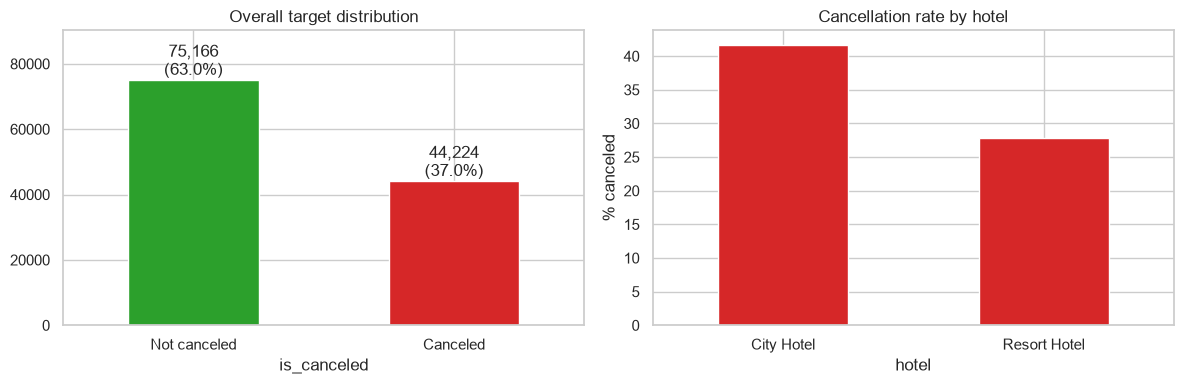

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
counts = df_raw[TARGET].map({0: "Not canceled", 1: "Canceled"}).value_counts()
counts.plot.bar(ax=axes[0], color=["tab:green", "tab:red"], rot=0)
for i, v in enumerate(counts):
    axes[0].text(i, v, f"{v:,}\n({v / len(df_raw):.1%})", ha="center", va="bottom")
axes[0].set_title("Overall target distribution")
axes[0].set_ylim(0, counts.max() * 1.2)
rate = df_raw.groupby("hotel")[TARGET].mean().mul(100)
rate.plot.bar(ax=axes[1], color="tab:red", rot=0)
axes[1].set_ylabel("% canceled")
axes[1].set_title("Cancellation rate by hotel")
plt.tight_layout()
plt.show()

### 3.2 Numeric distributions
The histograms are clipped at the 99.5th percentile so that a few extreme values don't squash the plot.

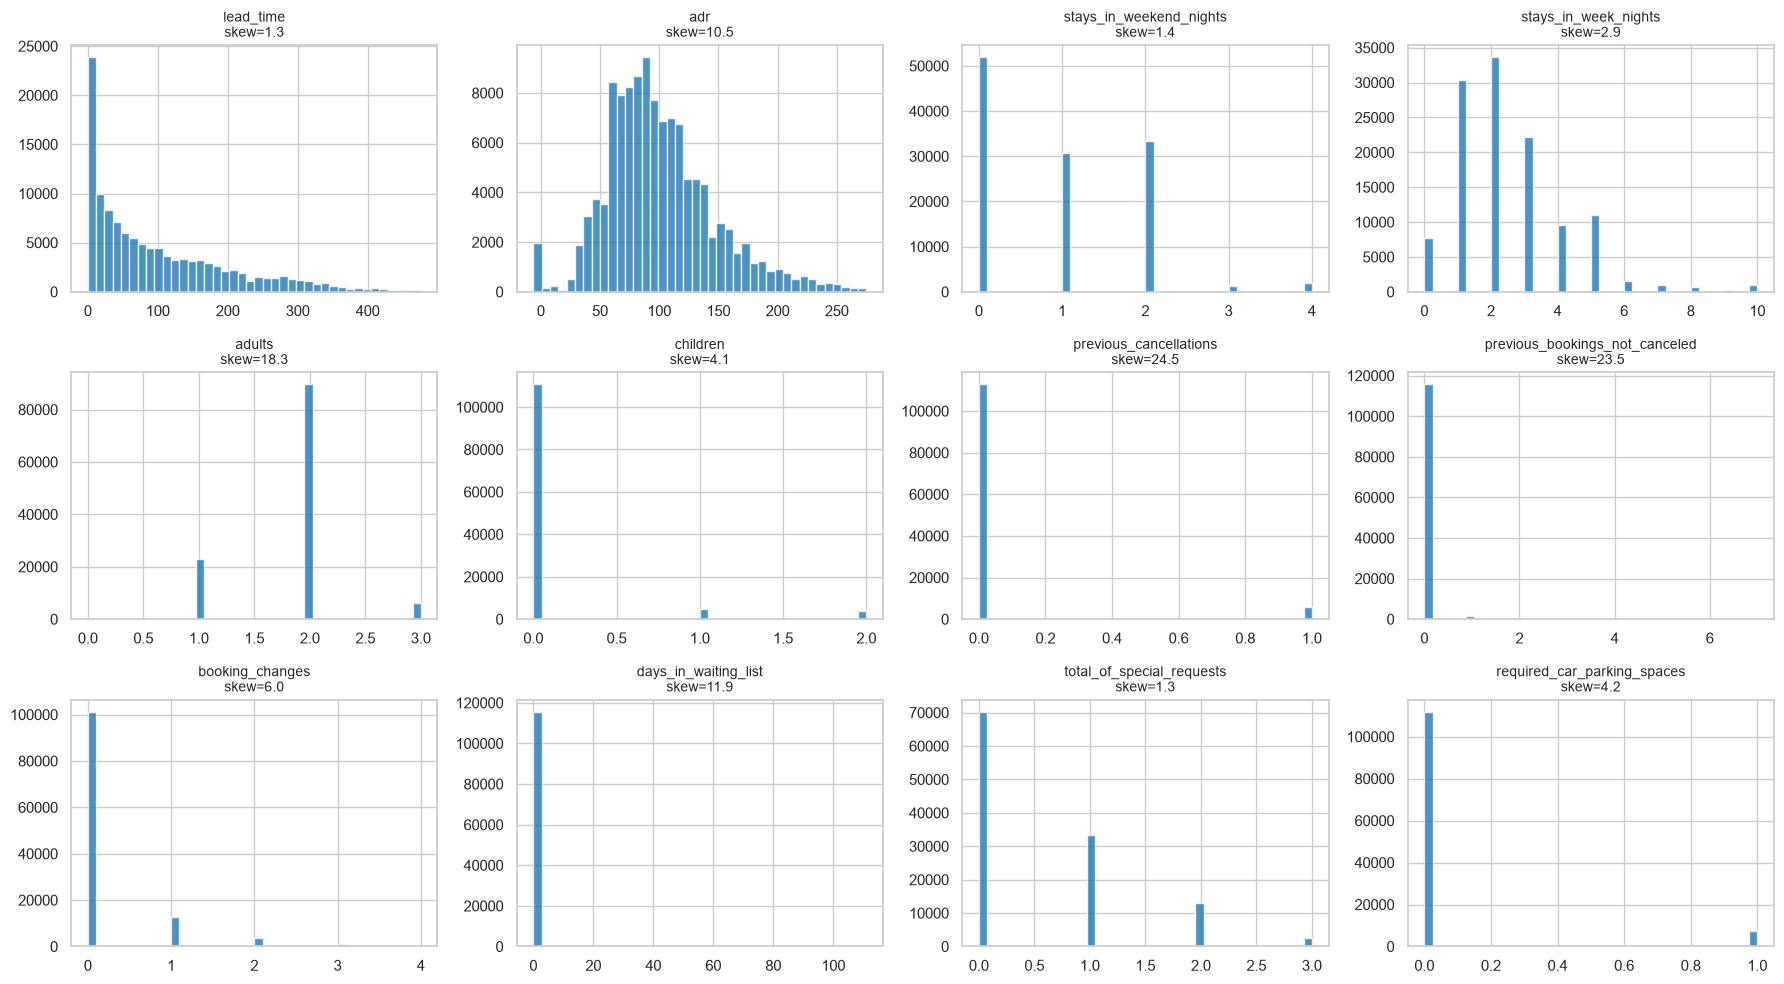

In [15]:
NUM_EDA = ["lead_time", "adr", "stays_in_weekend_nights", "stays_in_week_nights", "adults", "children",
           "previous_cancellations", "previous_bookings_not_canceled", "booking_changes",
           "days_in_waiting_list", "total_of_special_requests", "required_car_parking_spaces"]
fig, axes = plt.subplots(3, 4, figsize=(18, 10))
for ax, col in zip(axes.flat, NUM_EDA):
    s = df_raw[col].dropna()
    s = s[s <= s.quantile(0.995)]
    ax.hist(s, bins=40, color="tab:blue", alpha=0.8)
    ax.set_title(f"{col}\nskew={df_raw[col].skew():.1f}", fontsize=10)
plt.tight_layout()
plt.show()

### 3.3 Lead time vs cancellation

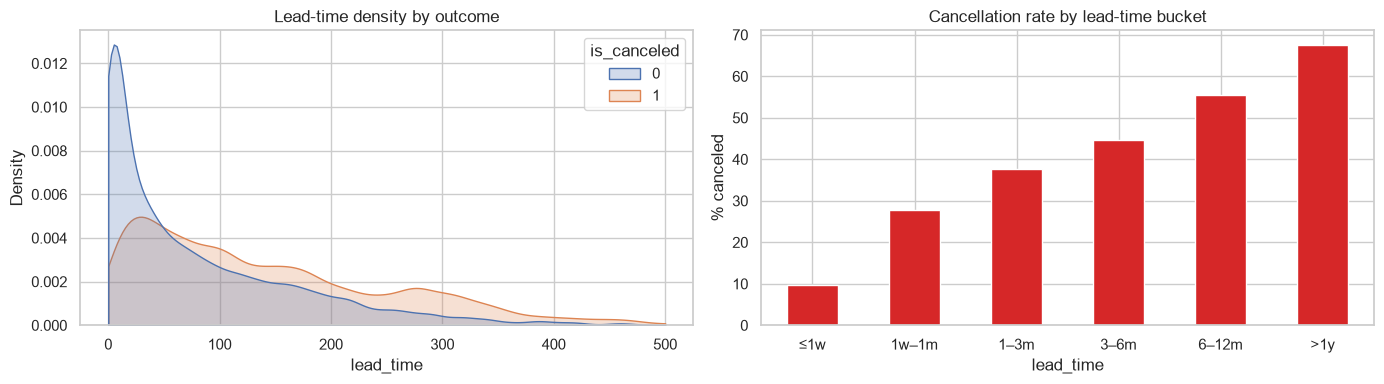

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.kdeplot(data=df_raw, x="lead_time", hue=TARGET, common_norm=False, fill=True, clip=(0, 500), ax=axes[0])
axes[0].set_title("Lead-time density by outcome")
bins = pd.cut(df_raw["lead_time"], [-1, 7, 30, 90, 180, 365, 800],
              labels=["≤1w", "1w–1m", "1–3m", "3–6m", "6–12m", ">1y"])
df_raw.groupby(bins, observed=True)[TARGET].mean().mul(100).plot.bar(ax=axes[1], color="tab:red", rot=0)
axes[1].set_ylabel("% canceled")
axes[1].set_title("Cancellation rate by lead-time bucket")
plt.tight_layout()
plt.show()

### 3.4 Cancellation rate across categorical features
Bar = cancellation rate, label = number of bookings in that category.

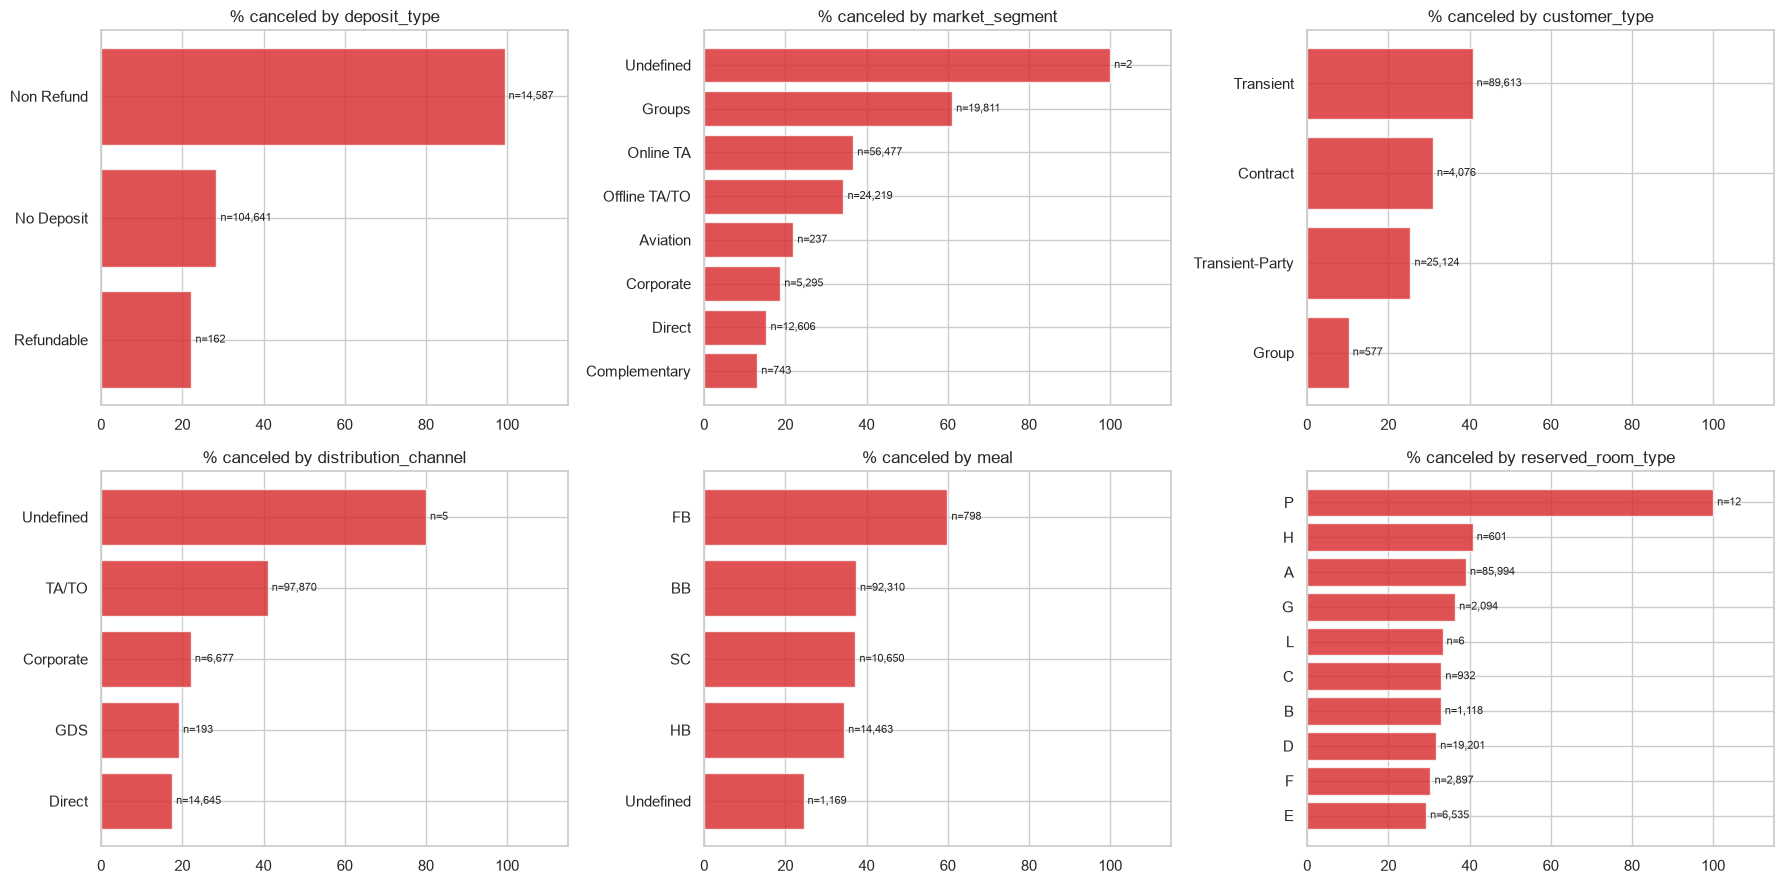

In [17]:
def rate_plot(col, ax, top=None):
    g = df_raw.groupby(col)[TARGET].agg(["mean", "size"]).sort_values("size", ascending=False)
    if top:
        g = g.head(top)
    g = g.sort_values("mean")
    ax.barh(g.index.astype(str), g["mean"] * 100, color="tab:red", alpha=0.8)
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(m * 100 + 1, i, f"n={n:,}", va="center", fontsize=8)
    ax.set_xlim(0, 115)
    ax.set_title(f"% canceled by {col}")


fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, col in zip(axes.flat, ["deposit_type", "market_segment", "customer_type",
                               "distribution_channel", "meal", "reserved_room_type"]):
    rate_plot(col, ax)
plt.tight_layout()
plt.show()

### 3.5 Seasonality: arrivals and price by month

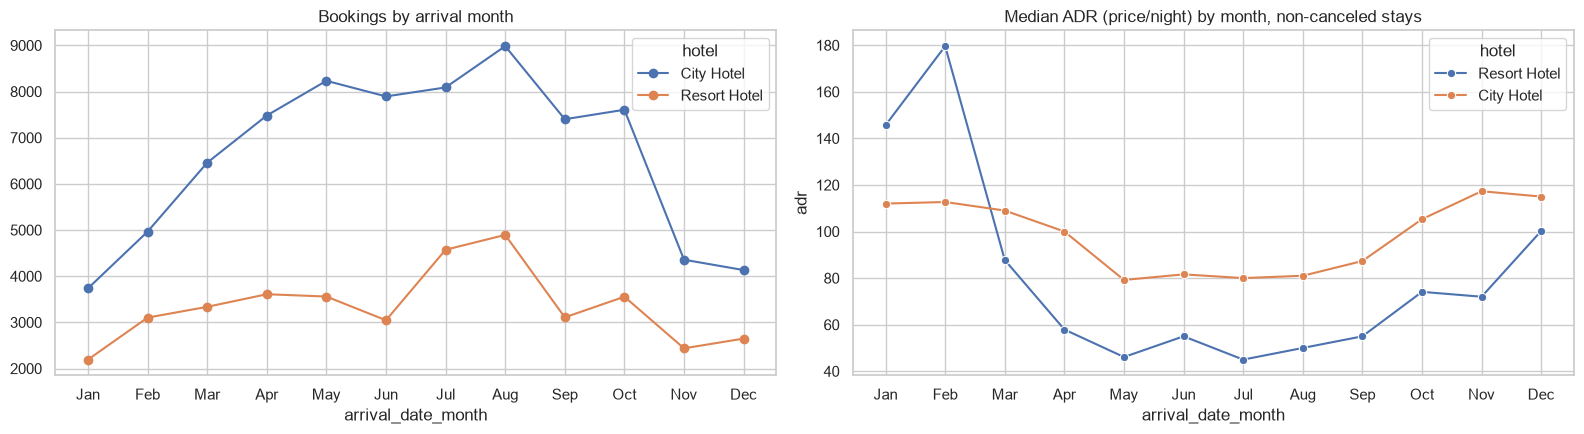

In [18]:
MONTHS = ["January", "February", "March", "April", "May", "June", "July",
          "August", "September", "October", "November", "December"]
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
arr = df_raw.groupby(["arrival_date_month", "hotel"]).size().unstack().reindex(MONTHS)
arr.plot(ax=axes[0], marker="o")
axes[0].set_title("Bookings by arrival month")
axes[0].set_xticks(range(12))
axes[0].set_xticklabels([m[:3] for m in MONTHS])
ok = df_raw[(df_raw[TARGET] == 0) & df_raw["adr"].between(0, 1000)]
sns.lineplot(data=ok, x="arrival_date_month", y="adr", hue="hotel", estimator="median", errorbar=None,
             ax=axes[1], marker="o", sort=False)
axes[1].set_xticks(range(12))
axes[1].set_xticklabels([m[:3] for m in MONTHS])
axes[1].set_title("Median ADR (price/night) by month, non-canceled stays")
plt.tight_layout()
plt.show()

### 3.6 Where do guests come from?

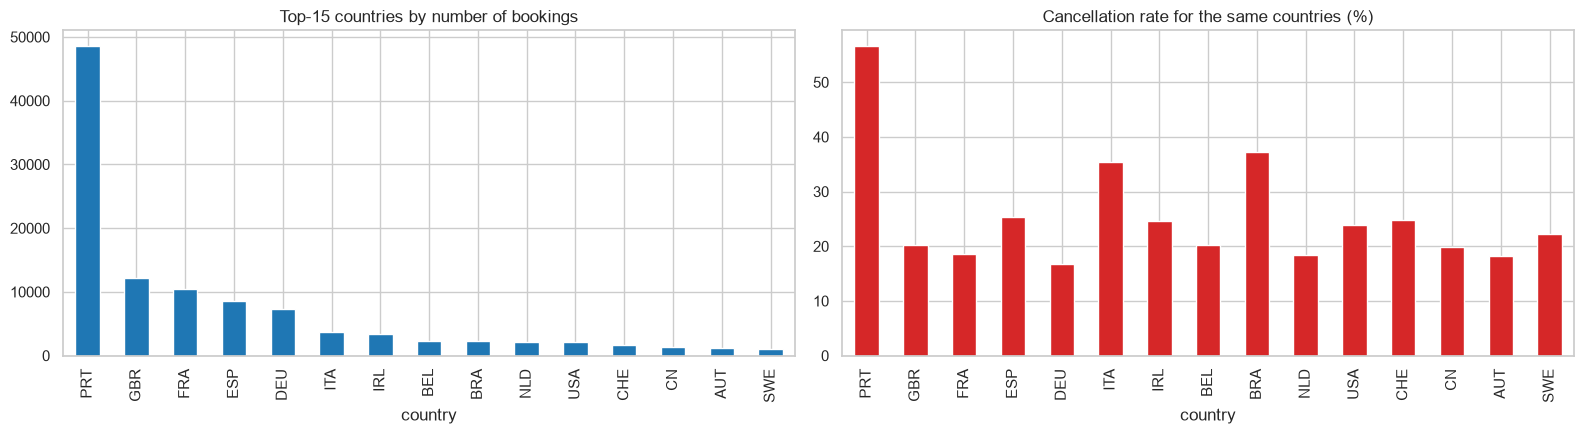

177 distinct countries; top-15 cover 90.6% of bookings


In [19]:
top_c = df_raw["country"].value_counts().head(15)
fig, axes = plt.subplots(1, 2, figsize=(16, 4.5))
top_c.plot.bar(ax=axes[0], color="tab:blue")
axes[0].set_title("Top-15 countries by number of bookings")
df_raw[df_raw["country"].isin(top_c.index)].groupby("country")[TARGET].mean().mul(100) \
    .reindex(top_c.index).plot.bar(ax=axes[1], color="tab:red")
axes[1].set_title("Cancellation rate for the same countries (%)")
plt.tight_layout()
plt.show()
print(f"{df_raw['country'].nunique()} distinct countries; top-15 cover {top_c.sum() / len(df_raw):.1%} of bookings")

### 3.7 Correlations (Spearman, numeric columns + target)
Spearman (rank) correlation is used because most numeric columns are heavily skewed or count-like.

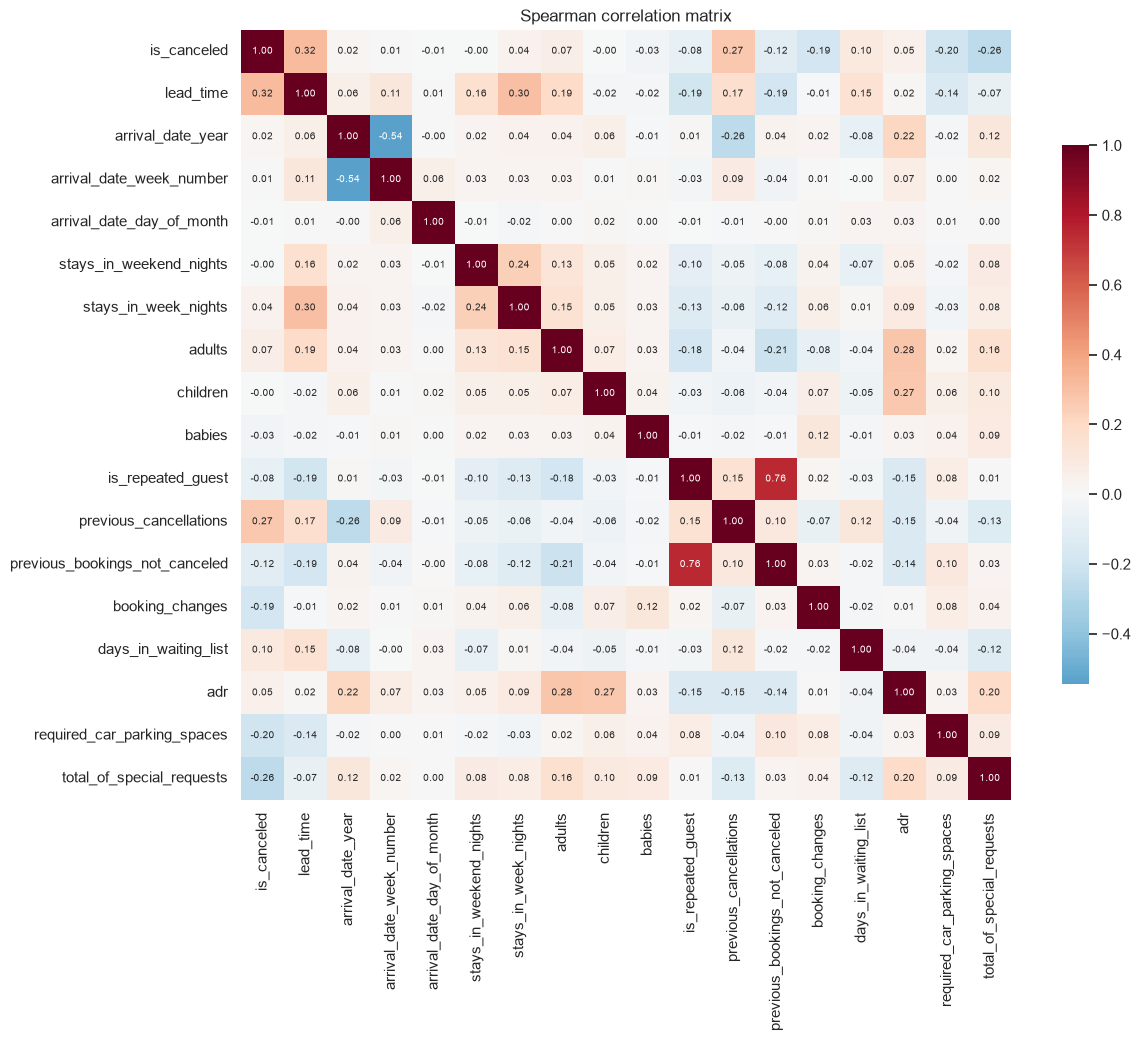

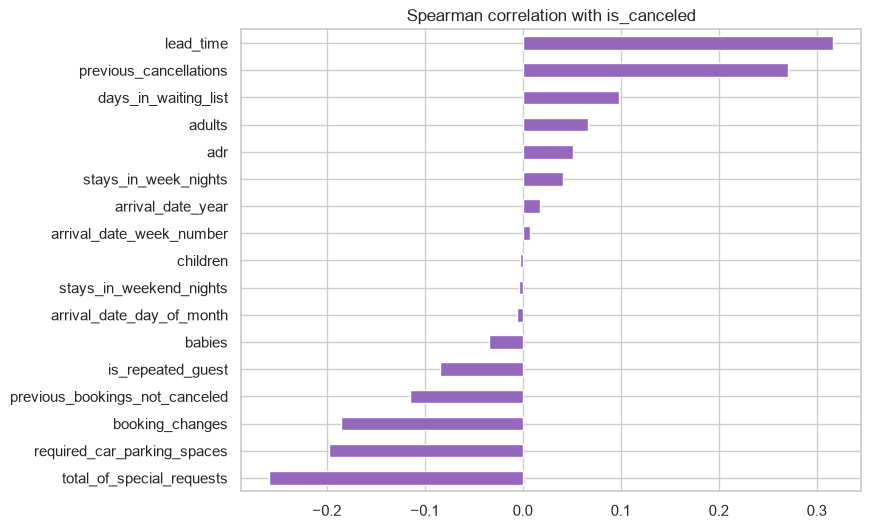

In [20]:
num_all = df_raw.select_dtypes("number").drop(columns=["agent", "company"])
corr = num_all.corr(method="spearman")
plt.figure(figsize=(13, 10))
sns.heatmap(corr, cmap="RdBu_r", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, square=True, cbar_kws={"shrink": .7})
plt.title("Spearman correlation matrix")
plt.show()
corr[TARGET].drop(TARGET).sort_values().plot.barh(figsize=(8, 6), color="tab:purple",
                                                   title=f"Spearman correlation with {TARGET}")
plt.show()

### 3.8 Guest-history and special-request signals

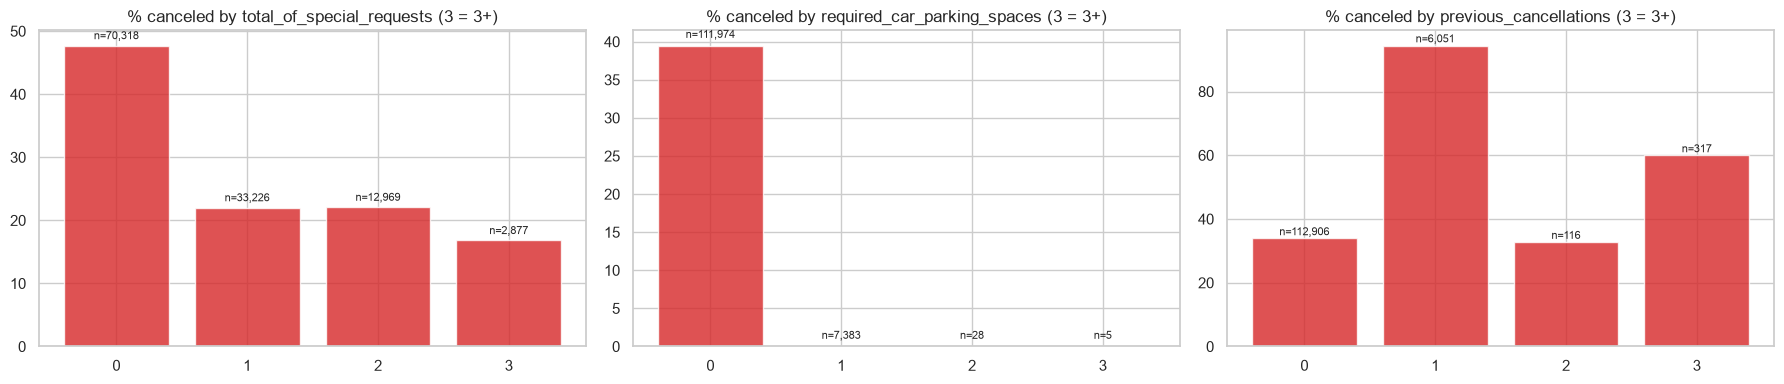

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
for ax, col in zip(axes, ["total_of_special_requests", "required_car_parking_spaces", "previous_cancellations"]):
    g = df_raw.assign(v=df_raw[col].clip(upper=3)).groupby("v")[TARGET].agg(["mean", "size"])
    ax.bar(g.index.astype(str), g["mean"] * 100, color="tab:red", alpha=.8)
    for i, (m, n) in enumerate(zip(g["mean"], g["size"])):
        ax.text(i, m * 100 + 1, f"n={n:,}", ha="center", fontsize=8)
    ax.set_title(f"% canceled by {col} (3 = 3+)")
plt.tight_layout()
plt.show()

> ✍️ **Your observations (EDA):** what drives cancellations? Consider lead time, deposit type (the *Non Refund* surprise, explained in 2.5), market segment, special requests, seasonality and country. Parking looks like the perfect predictor (0% cancel). Why is that a red flag rather than an insight (2.4)? Which genuine drivers do you expect the models to rank highly?

## 4. Automated EDA with AutoViz
AutoViz (from the same authors as AutoViML) profiles every column automatically. It prints data-cleaning suggestions and draws distributions, scatter plots and pair plots against the target and a correlation heatmap. Compare what it flags with the manual audit above. The leakage columns are excluded.

Imported v0.1.905. Please call AutoViz in this sequence:
    AV = AutoViz_Class()
    %matplotlib inline
    dfte = AV.AutoViz(filename, sep=',', depVar='', dfte=None, header=0, verbose=1, lowess=False,
               chart_format='svg',max_rows_analyzed=150000,max_cols_analyzed=30, save_plot_dir=None)
    Since nrows is smaller than dataset, loading random sample of 20000 rows into pandas...
Shape of your Data Set loaded: (20000, 30)
#######################################################################################
######################## C L A S S I F Y I N G  V A R I A B L E S  ####################
#######################################################################################
Classifying variables in data set...
    Number of Numeric Columns =  3
    Number of Integer-Categorical Columns =  13
    Number of String-Categorical Columns =  9
    Number of Factor-Categorical Columns =  0
    Number of String-Boolean Columns =  1
    Number of Numeric-Boolean Columns =  1


    All variables classified into correct types.


,Data Type,Missing Values%,Unique Values%,Minimum Value,Maximum Value,DQ Issue
hotel,object,0.000000,0,,,No issue
lead_time,int64,0.000000,2,0.000000,629.000000,Column has 476 outliers greater than upper bound (319.00) or lower than lower bound(-169.00). Cap them or remove them.
arrival_date_year,int64,0.000000,0,2015.000000,2017.000000,Possible date-time colum: transform before modeling step.
arrival_date_month,object,0.000000,0,,,No issue
arrival_date_week_number,int64,0.000000,0,1.000000,53.000000,No issue
arrival_date_day_of_month,int64,0.000000,0,1.000000,31.000000,No issue
stays_in_weekend_nights,int64,0.000000,0,0.000000,12.000000,Column has 41 outliers greater than upper bound (5.00) or lower than lower bound(-3.00). Cap them or remove them.
stays_in_week_nights,int64,0.000000,0,0.000000,30.000000,Column has 539 outliers greater than upper bound (6.00) or lower than lower bound(-2.00). Cap them or remove them.
adults,int64,0.000000,0,0.000000,26.000000,Column has 4289 outliers greater than upper bound (2.00) or lower than lower bound(2.00). Cap them or remove them.
children,float64,0.011883,NA,0.000000,3.000000,"2 missing values. Impute them with mean, median, mode, or a constant value such as 123., Column has 1436 outliers greater than upper bound (0.00) or lower than lower bound(0.00). Cap them or remove them."


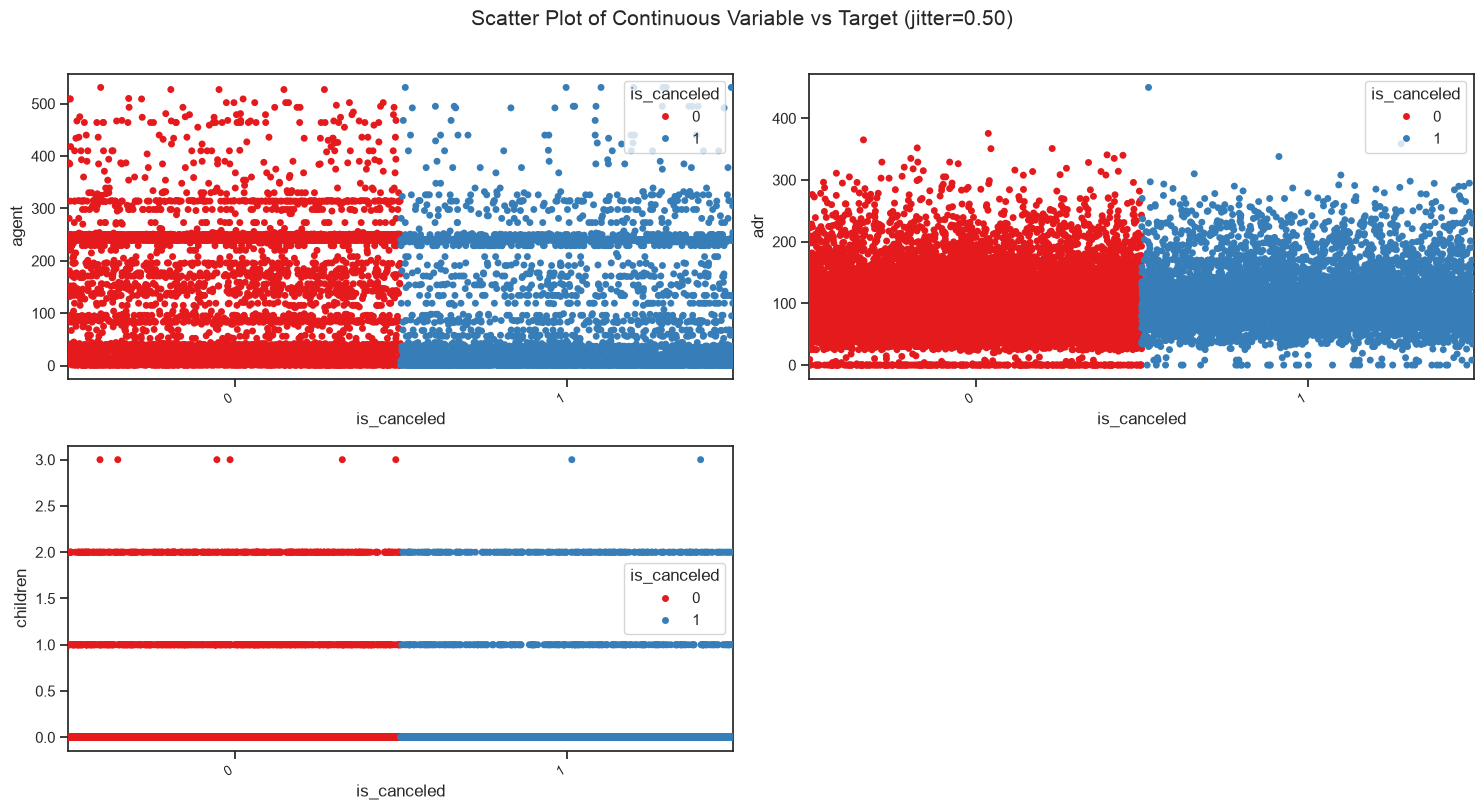

Total Number of Scatter Plots = 6


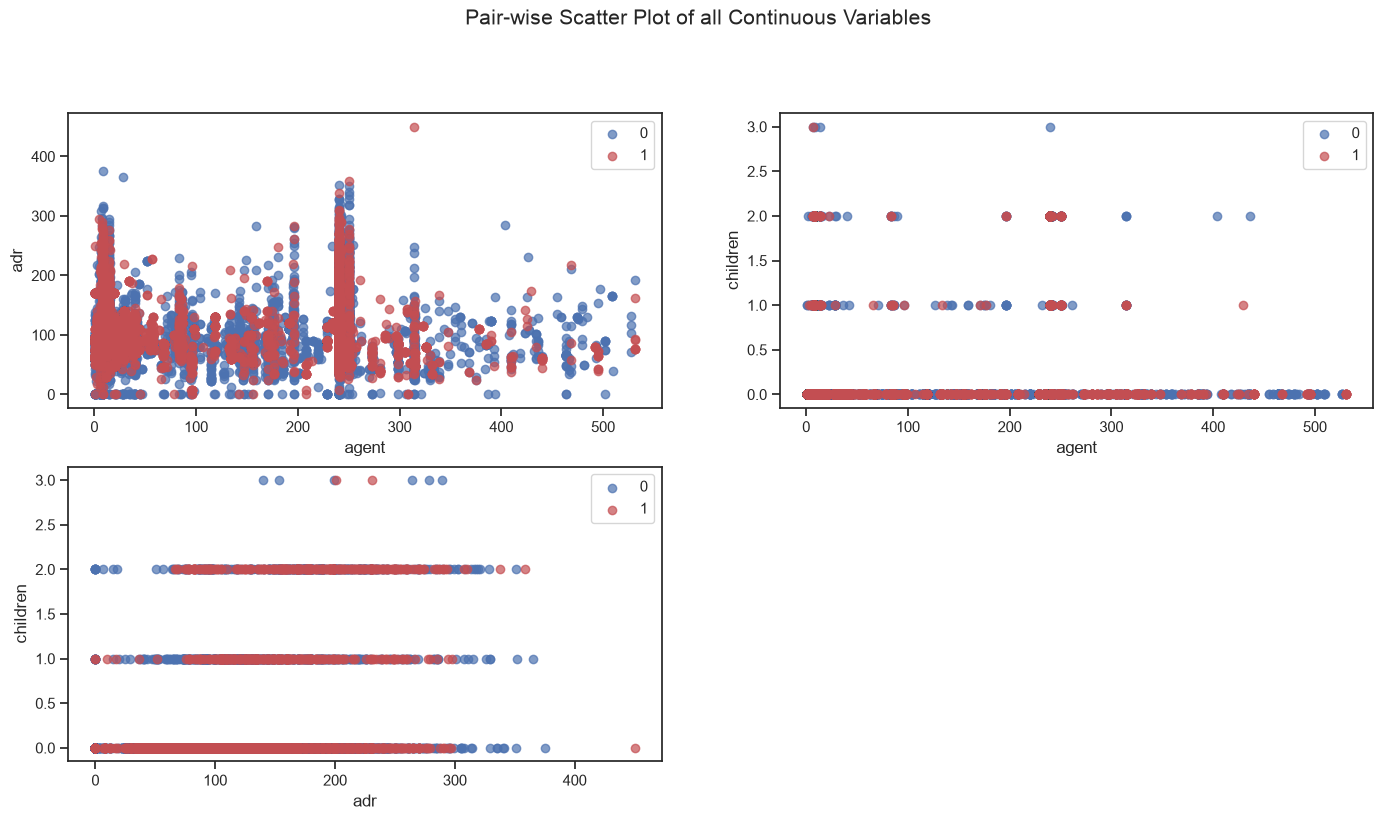

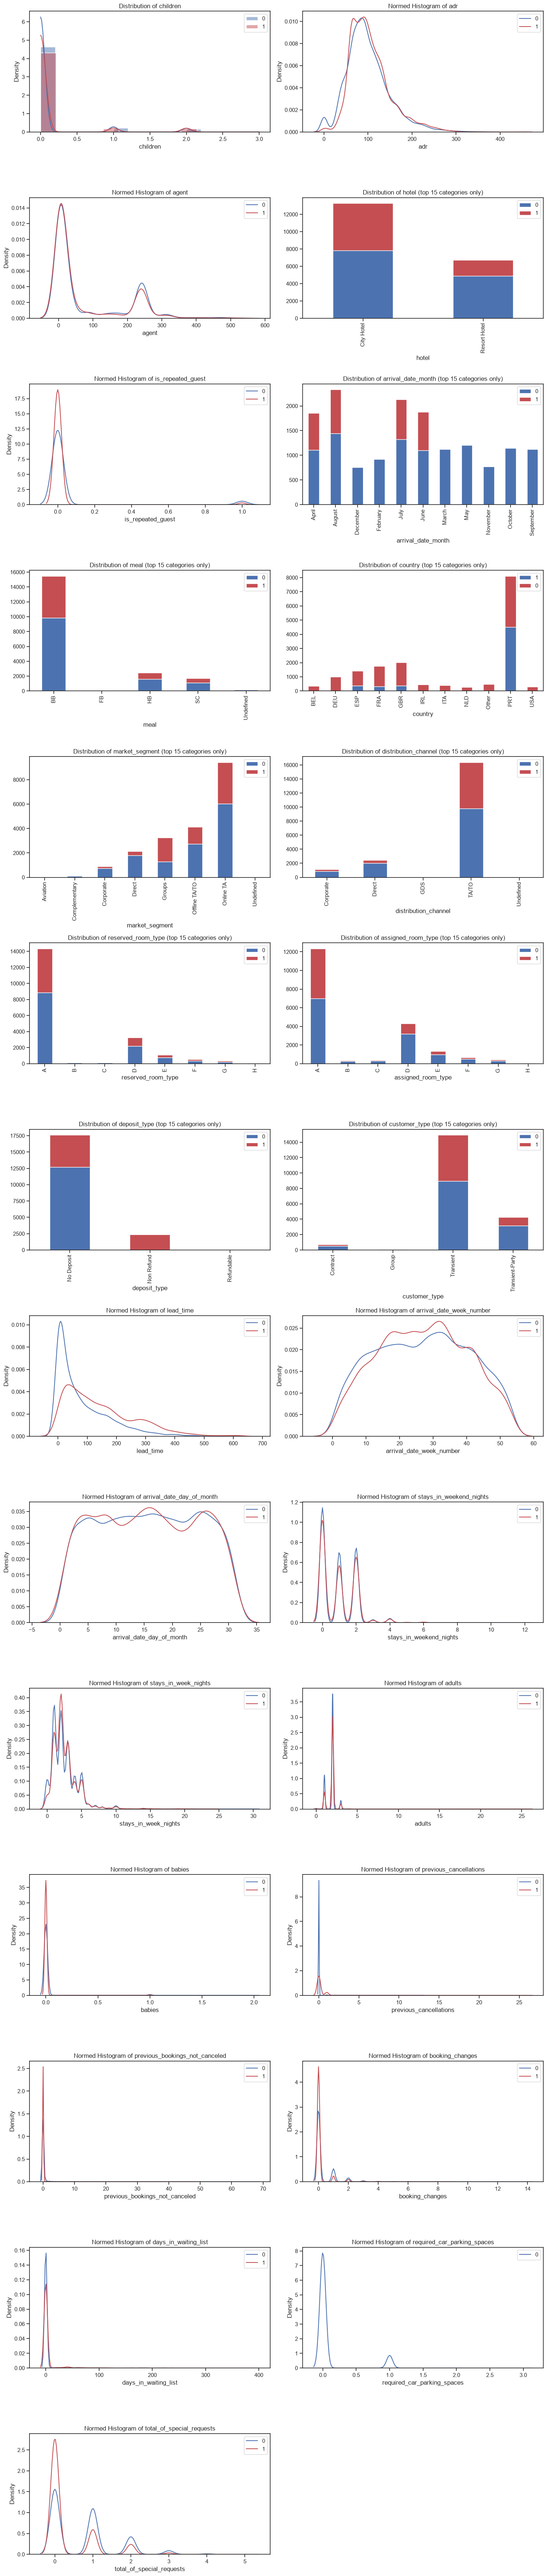

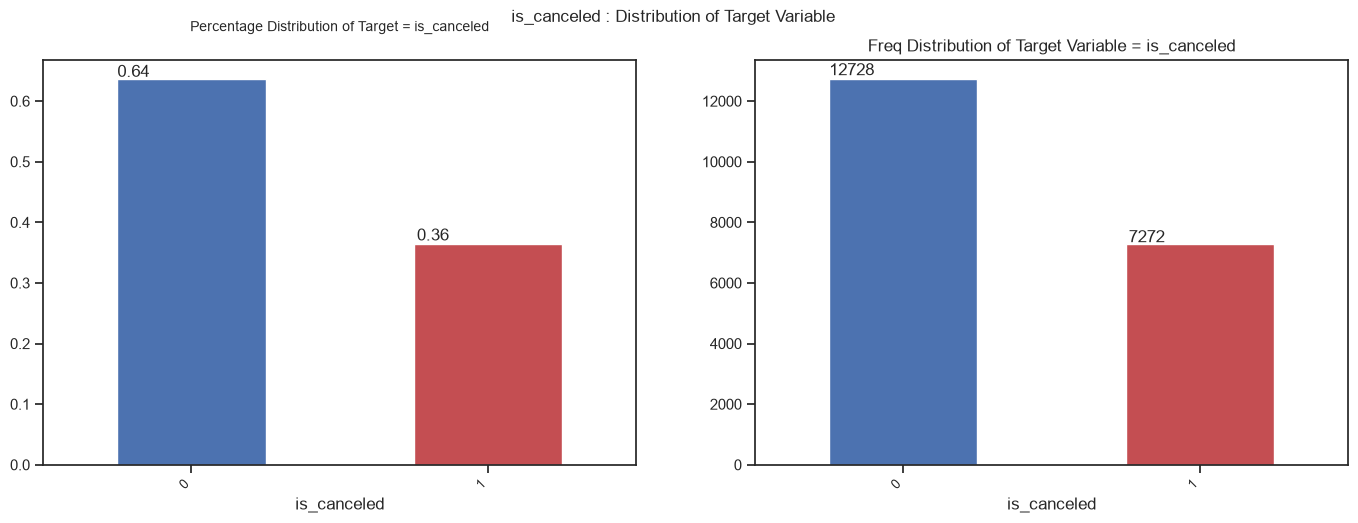

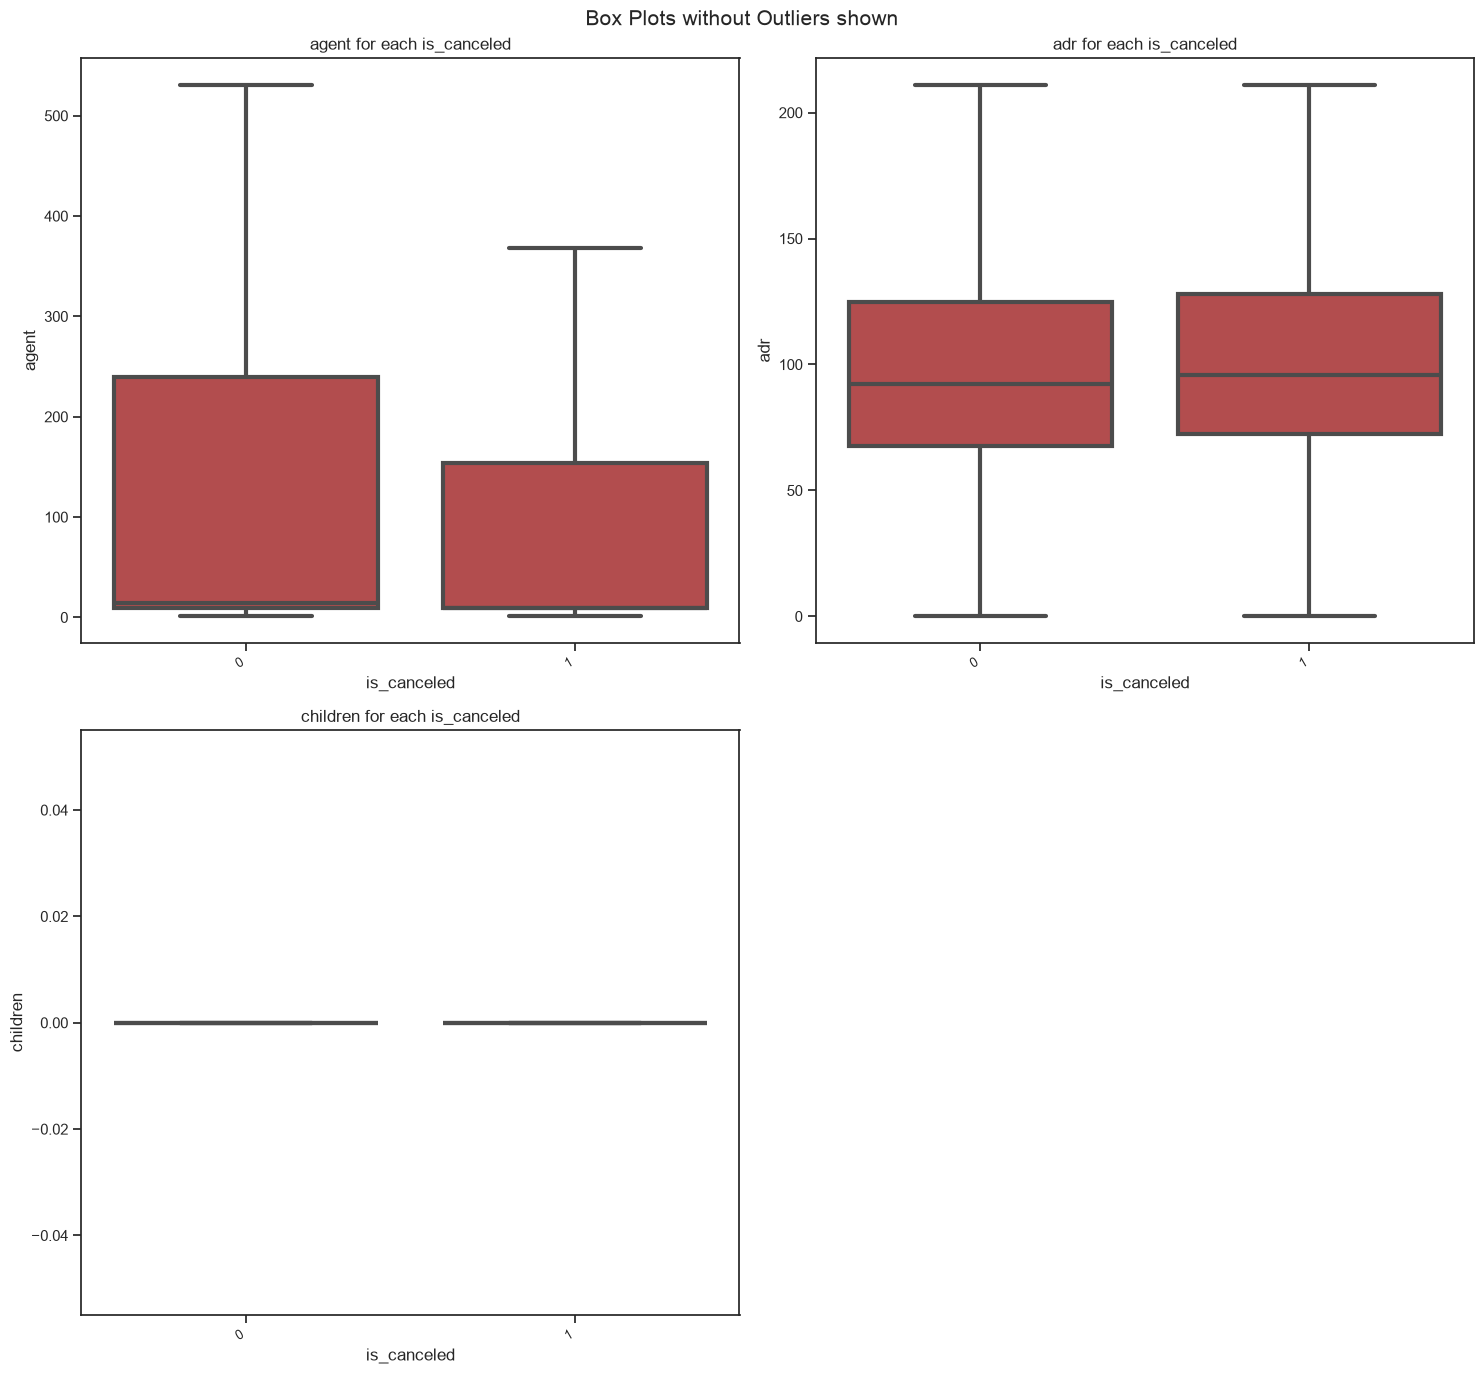

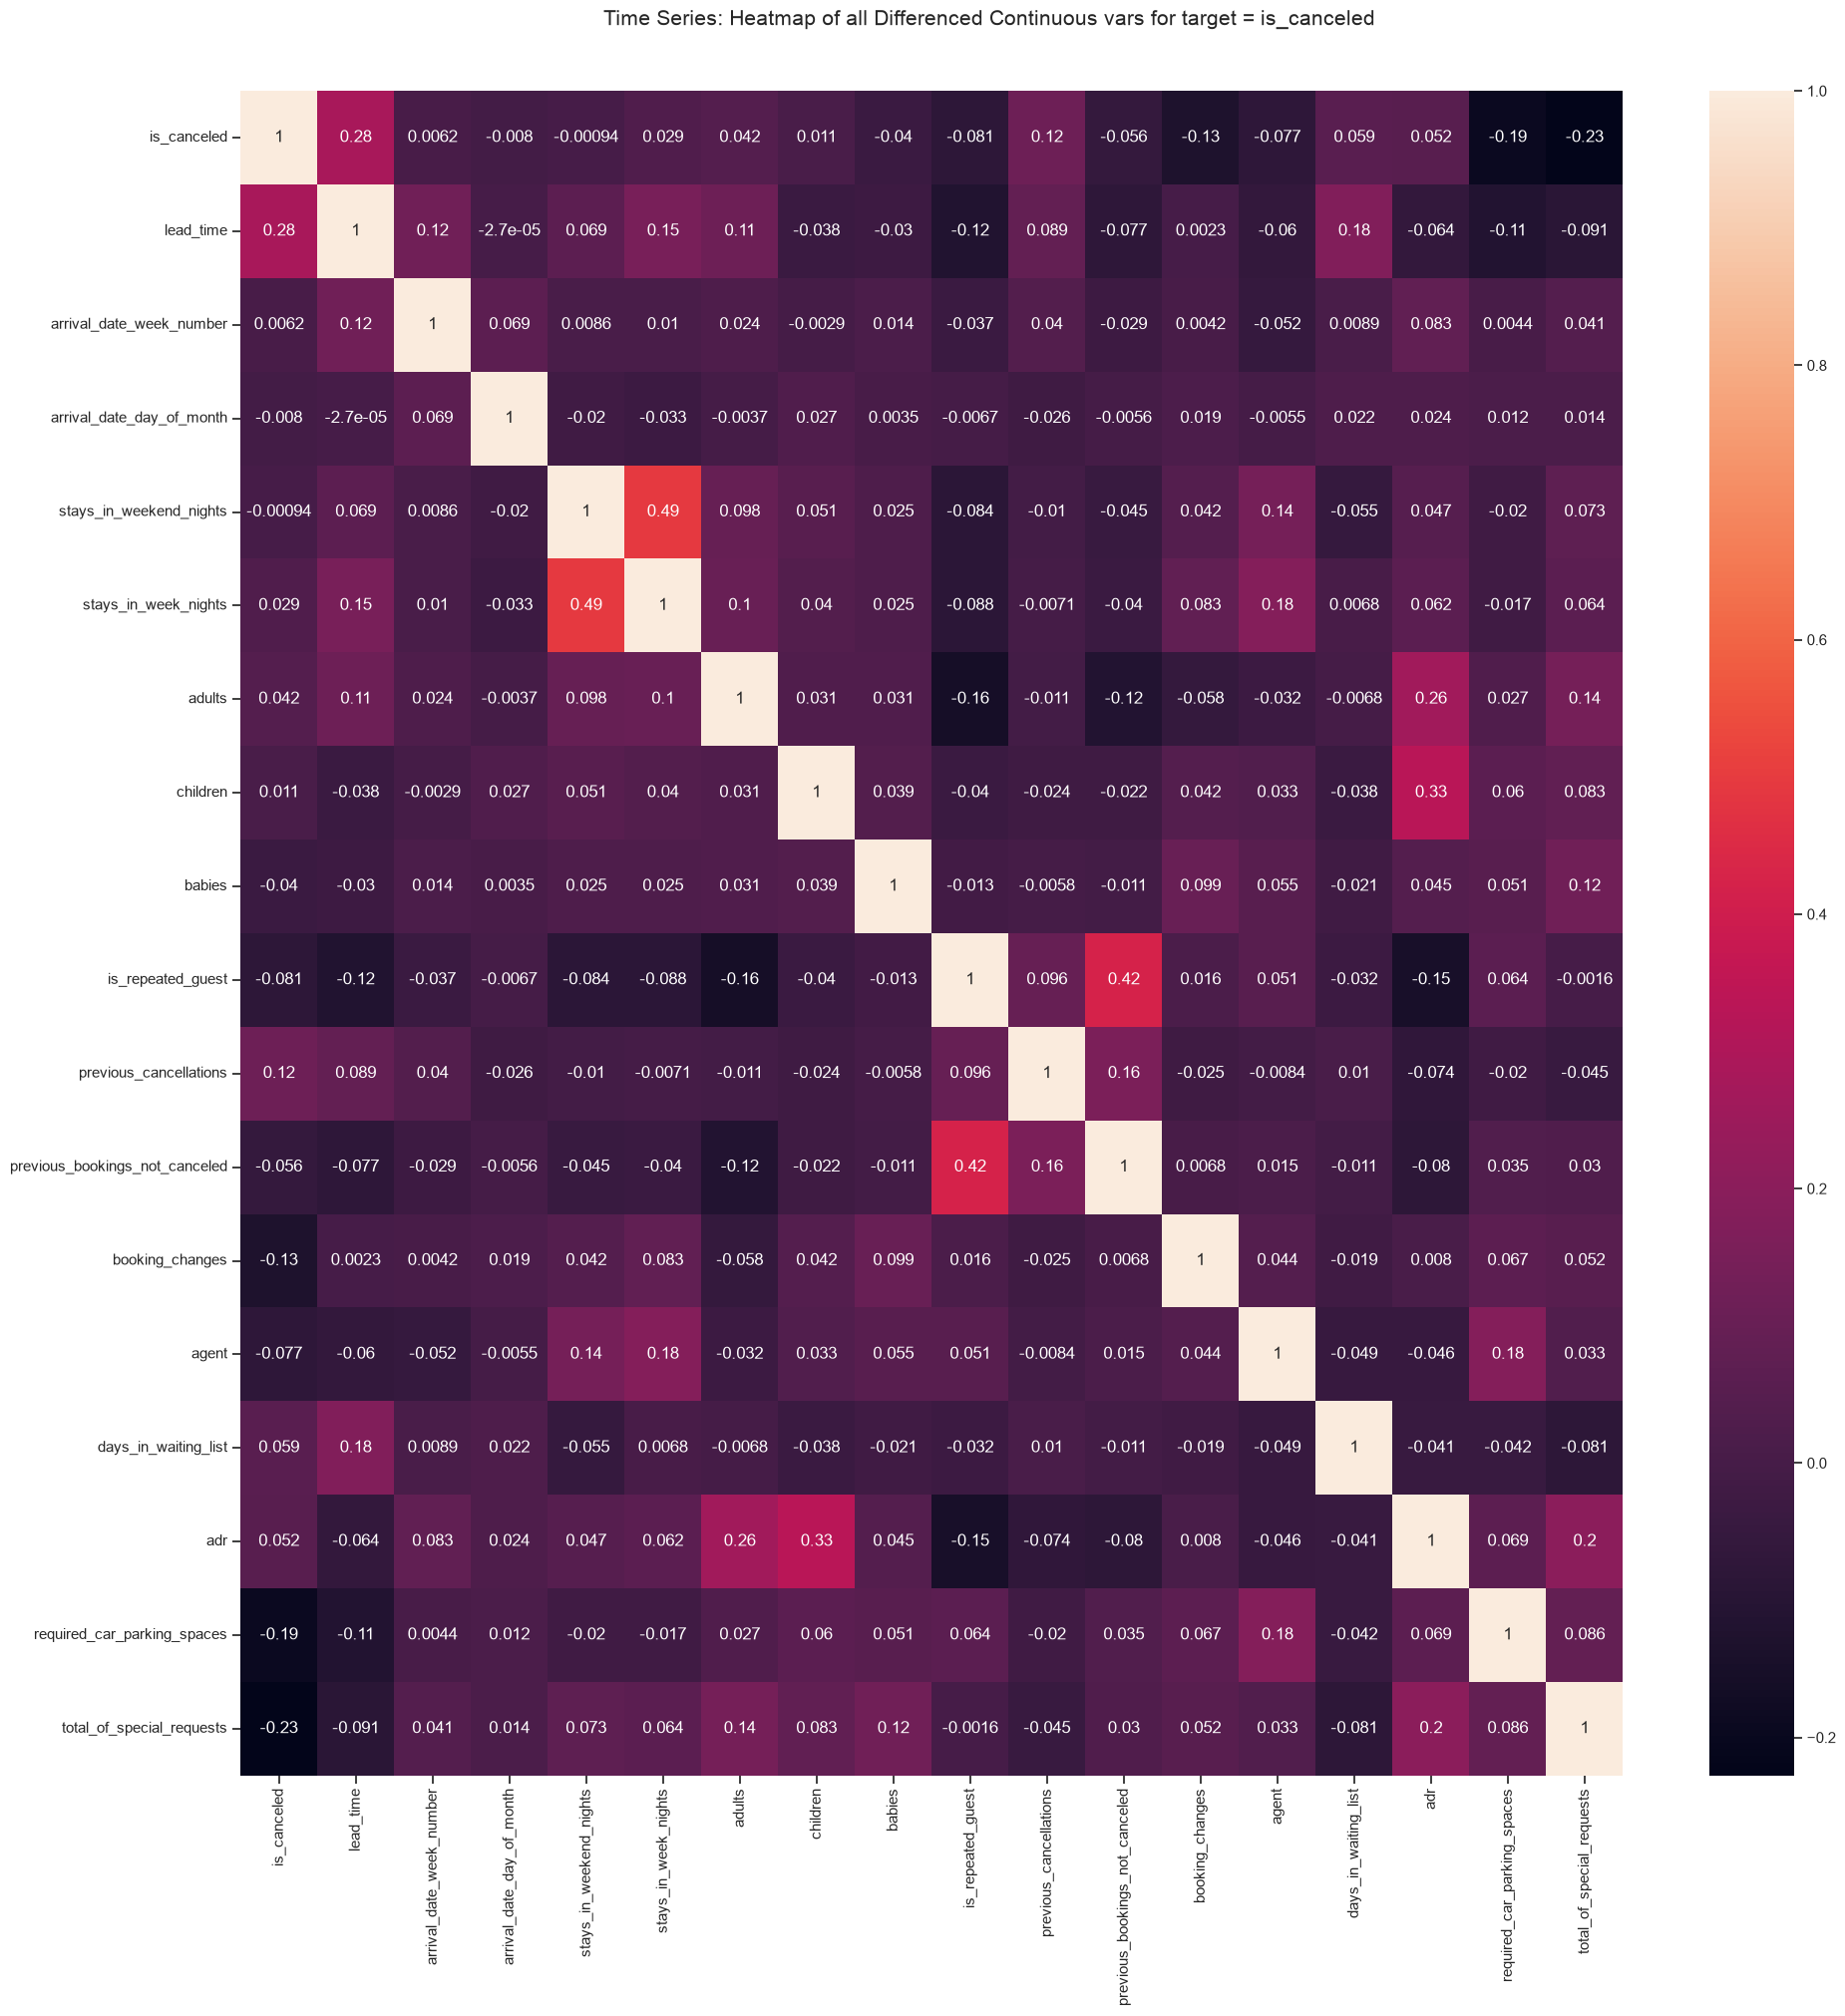

arrival_date_year could not be indexed. Could not draw date_vars.




All Plots done
Time to run AutoViz = 6 seconds 

 ###################### AUTO VISUALIZATION Completed ########################


In [22]:
if RUN_AUTOVIZ:
    from autoviz import AutoViz_Class
    %matplotlib inline
    # NB: importing autoviz switches matplotlib to the non-interactive 'agg' backend, so inline plotting is re-enabled
    # straight after the import (and again below for the rest of the notebook).
    # 'country' (178 codes) is grouped to its top 30 so AutoViz treats it as a category rather than free text
    # (free text would make it draw a word cloud and download ~400 MB of NLTK corpora).
    av_df = df_raw.drop(columns=["reservation_status", "reservation_status_date"])
    av_df["country"] = av_df["country"].where(av_df["country"].isin(av_df["country"].value_counts().head(30).index), "Other")
    AV = AutoViz_Class()
    _ = AV.AutoViz(filename="", dfte=av_df, depVar=TARGET, verbose=1, chart_format="png",
                   max_rows_analyzed=20000, max_cols_analyzed=30)
%matplotlib inline

> ✍️ **Your observations (AutoViz vs manual):** what did AutoViz flag that you had also found? What did it miss, such as leakage or the "Undefined" categories?

## 5. Cleaning
These are deterministic, row-level fixes that don't learn any statistics, so they are safe to apply **before** the train/test split. They are wrapped in a function so that section 7 can rebuild the data **without** deduplication and measure what that choice does. Each step is logged.

`required_car_parking_spaces` and `country` are **kept for now**. Their leakage impact is measured in section 7 and they are dropped there.

In [23]:
LEAKAGE_COLS = ["reservation_status", "reservation_status_date", "assigned_room_type"]


def clean(d, dedupe=True, log=None):
    def log_step(step, before, after, reason):
        if log is not None:
            log.append({"step": step, "rows_before": before, "rows_after": after,
                        "rows_removed": before - after, "reason": reason})

    d = d.copy()
    # 5.1 Exact duplicates (see 2.5): no booking ID, so identical rows can't be told apart
    if dedupe:
        n = len(d); d = d.drop_duplicates()
        log_step("Drop exact duplicate rows", n, len(d), "mostly one cancelled group block counted many times (2.5)")
    # 5.2 Outcome columns: only known after the outcome
    d = d.drop(columns=LEAKAGE_COLS)
    log_step("Drop outcome/leakage columns " + ", ".join(LEAKAGE_COLS), len(d), len(d), "only known after the outcome")
    # 5.3 Impossible rows: bookings with no guests
    n = len(d)
    d = d[(d["adults"] + d["children"].fillna(0) + d["babies"]) > 0]
    log_step("Drop bookings with zero guests", n, len(d), "a stay with no guests is a data-entry error")
    # 5.4 Standardise categories. 'Undefined' and 'SC' both mean 'no meal package' (data dictionary)
    d["meal"] = d["meal"].replace("Undefined", "SC")
    for c in ["market_segment", "distribution_channel"]:
        d[c] = d[c].replace("Undefined", np.nan)       # true unknowns, imputed later
    log_step("meal Undefined→SC; segment/channel Undefined→NaN", len(d), len(d), "consistent category labels")
    # 5.5 Fix types: agent/company are IDs, not quantities
    d["has_agent"] = d["agent"].notna().astype(int)
    d["has_company"] = d["company"].notna().astype(int)
    d["agent"] = d["agent"].map(lambda v: np.nan if pd.isna(v) else f"agent_{int(v)}")
    d = d.drop(columns="company")                       # ~94% empty: keep only the has_company flag
    log_step("agent→categorical; company→has_company flag", len(d), len(d), "IDs are labels, not numbers")
    # 5.6 Build a real arrival date from the 4 split columns
    d["arrival_month_num"] = d["arrival_date_month"].map({m: i + 1 for i, m in enumerate(MONTHS)})
    d["arrival_date"] = pd.to_datetime(dict(year=d["arrival_date_year"], month=d["arrival_month_num"],
                                            day=d["arrival_date_day_of_month"]))
    # 5.7 Implausible prices become missing values (imputed later, using train-only statistics)
    bad_adr = (d["adr"] < 0) | (d["adr"] > 1000)
    d.loc[bad_adr, "adr"] = np.nan
    log_step("adr <0 or >1000 → NaN", len(d), len(d), f"{bad_adr.sum()} implausible prices sent to imputation")
    return d


base = df_raw.sample(frac=SAMPLE_FRAC, random_state=RANDOM_STATE) if SAMPLE_FRAC < 1 else df_raw
clean_log = []
df = clean(base, dedupe=True, log=clean_log)
df_with_dups = clean(base, dedupe=False)          # only used for the sensitivity check in 7.2
pd.DataFrame(clean_log)

,step,rows_before,rows_after,rows_removed,reason
0,Drop exact duplicate rows,119390,87396,31994,mostly one cancelled group block counted many times (2.5)
1,"Drop outcome/leakage columns reservation_status, reservation_status_date, assigned_room_type",87396,87396,0,only known after the outcome
2,Drop bookings with zero guests,87396,87230,166,a stay with no guests is a data-entry error
3,meal Undefined→SC; segment/channel Undefined→NaN,87230,87230,0,consistent category labels
4,agent→categorical; company→has_company flag,87230,87230,0,"IDs are labels, not numbers"
5,adr <0 or >1000 → NaN,87230,87230,0,2 implausible prices sent to imputation


## 6. Chronological train/test split
Bookings form a **time series**: the cancellation rate rises every year, and the mix of agents, countries and channels shifts. A random split would let the model train on bookings that arrive *after* the ones it is tested on, which flatters the score. Instead:
* **train** = arrivals before the 80th-percentile arrival date
* **test** = every arrival from then on (about the last 4 months)

This matches how the model would really be used: trained on the past, then scoring future bookings. Identical duplicate rows share an arrival date, so copies can't straddle the boundary either.

Train: 2015-07-01 → 2017-05-01  (69686, 32)
Test:  2017-05-02 → 2017-08-31  (17544, 32)
Cancel rate train 0.257 | test 0.347  (drift!)


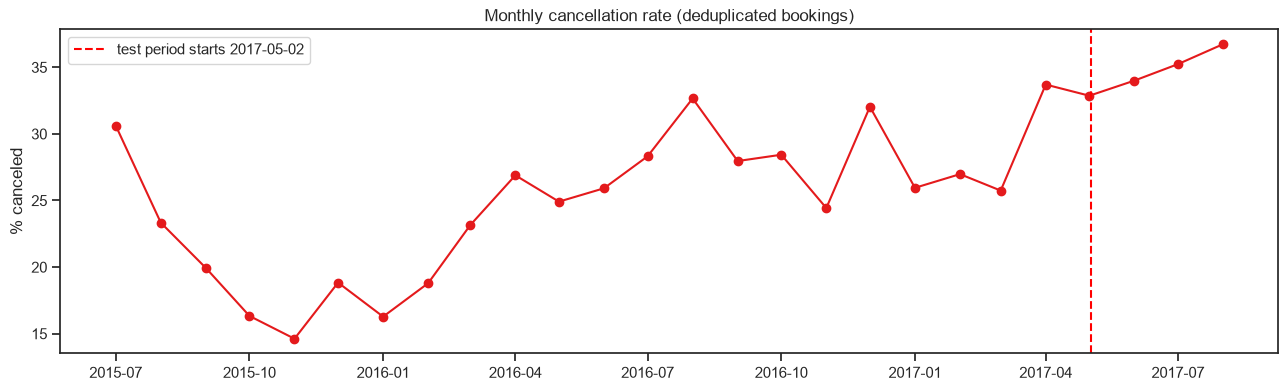

,train_missing,test_missing
children,4,0
country,447,0
market_segment,2,0
distribution_channel,5,0
agent,10618,1523
adr,2,0


In [24]:
TEST_START = df["arrival_date"].quantile(0.8).normalize()
train_df = df[df["arrival_date"] < TEST_START].copy()
test_df = df[df["arrival_date"] >= TEST_START].copy()
print(f"Train: {train_df['arrival_date'].min().date()} → {train_df['arrival_date'].max().date()}  {train_df.shape}")
print(f"Test:  {test_df['arrival_date'].min().date()} → {test_df['arrival_date'].max().date()}  {test_df.shape}")
print(f"Cancel rate train {train_df[TARGET].mean():.3f} | test {test_df[TARGET].mean():.3f}  (drift!)")

monthly = df.set_index("arrival_date").groupby(pd.Grouper(freq="MS"))[TARGET].agg(["mean", "size"])
fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(monthly.index, monthly["mean"] * 100, marker="o")
ax.axvline(TEST_START, color="red", ls="--", label=f"test period starts {TEST_START.date()}")
ax.set_ylabel("% canceled")
ax.set_title("Monthly cancellation rate (deduplicated bookings)")
ax.legend()
plt.show()
pd.DataFrame({"train_missing": train_df.isna().sum(), "test_missing": test_df.isna().sum()}).query("train_missing > 0 or test_missing > 0")

## 7. Sensitivity checks (training period only)
Three design decisions change the reported score: **how to split**, **whether to deduplicate**, and **which suspect features to keep**. Each is measured with the same quick model (a gradient-boosted tree with categories ordinal-encoded, no tuning). The training period is split again into **inner-train** (earlier) and **validation** (its last 20%), so the **test set is never used to make these decisions**.

In [25]:
from sklearn.ensemble import HistGradientBoostingClassifier

VAL_START = train_df["arrival_date"].quantile(0.8).normalize()
inner_tr = train_df[train_df["arrival_date"] < VAL_START]
inner_va = train_df[train_df["arrival_date"] >= VAL_START]


def quick_eval(tr, va, drop=()):
    feats = [c for c in tr.columns if c not in {TARGET, "arrival_date", *drop}]
    cats = [c for c in feats if tr[c].dtype == object]
    model = Pipeline([
        ("prep", ColumnTransformer([("cat", OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,
                                                           encoded_missing_value=-1), cats)],
                                   remainder="passthrough")),
        ("clf", HistGradientBoostingClassifier(class_weight="balanced", random_state=RANDOM_STATE)),
    ]).fit(tr[feats], tr[TARGET])
    p = model.predict_proba(va[feats])[:, 1]
    return {"ROC AUC": round(roc_auc_score(va[TARGET], p), 4),
            "balanced acc": round(balanced_accuracy_score(va[TARGET], p >= 0.5), 4),
            "train rows": len(tr), "train cancel rate": round(tr[TARGET].mean(), 3)}


print(f"inner-train: {len(inner_tr):,} rows (< {VAL_START.date()}) | validation: {len(inner_va):,} rows")

inner-train: 55,682 rows (< 2017-01-02) | validation: 14,004 rows


### 7.1 Random vs chronological split
* **chronological**: inner-train → later validation weeks (honest)
* **random, deduplicated**: same training period, shuffled 80/20
* **random, with duplicates**: shuffled *and* duplicates kept. Copies of the same booking land on both sides, so the model is partly tested on rows it has memorised.

In [26]:
period_dups = df_with_dups[df_with_dups["arrival_date"] < TEST_START]
r_tr, r_va = train_test_split(train_df, test_size=0.2, stratify=train_df[TARGET], random_state=RANDOM_STATE)
d_tr, d_va = train_test_split(period_dups, test_size=0.2, stratify=period_dups[TARGET], random_state=RANDOM_STATE)
split_res = pd.DataFrame({
    "chronological (used)": quick_eval(inner_tr, inner_va),
    "random, deduplicated": quick_eval(r_tr, r_va),
    "random, with duplicates": quick_eval(d_tr, d_va),
}).T
split_res

,ROC AUC,balanced acc,train rows,train cancel rate
chronological (used),0.8561,0.7749,55682.0,0.250
"random, deduplicated",0.9130,0.8292,55748.0,0.257
"random, with duplicates",0.9547,0.8783,77790.0,0.363


### 7.2 Deduplicate or not?
Both models are trained on the same inner-train period and scored on the **same deduplicated validation set** (each real booking counted once). The only difference is whether training keeps the duplicate rows.

In [27]:
dup_res = pd.DataFrame({
    "train deduplicated (used)": quick_eval(inner_tr, inner_va),
    "train with duplicates": quick_eval(period_dups[period_dups["arrival_date"] < VAL_START], inner_va),
}).T
dup_res

,ROC AUC,balanced acc,train rows,train cancel rate
train deduplicated (used),0.8561,0.7749,55682.0,0.250
train with duplicates,0.8560,0.7509,78717.0,0.362


### 7.3 Leaky and suspect features
How much of the score comes from the two features flagged in 2.4?

,ROC AUC,balanced acc,train rows,train cancel rate
all features,0.8561,0.7749,55682.0,0.25
− parking,0.8409,0.7620,55682.0,0.25
− parking − country,0.8187,0.7383,55682.0,0.25


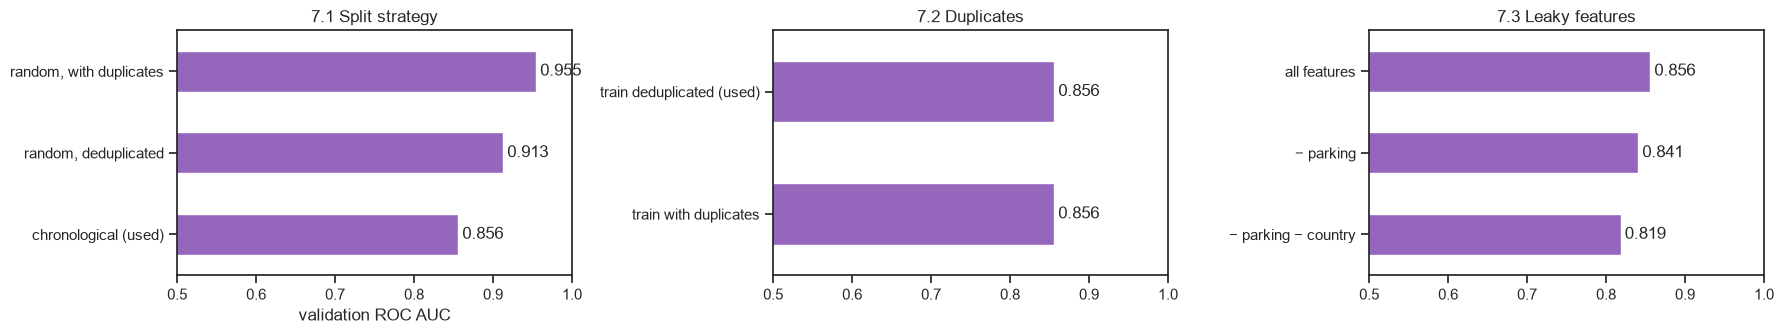

In [28]:
leak_res = pd.DataFrame({
    "all features": quick_eval(inner_tr, inner_va),
    "− parking": quick_eval(inner_tr, inner_va, drop=["required_car_parking_spaces"]),
    "− parking − country": quick_eval(inner_tr, inner_va, drop=["required_car_parking_spaces", "country"]),
}).T
display(leak_res)

fig, axes = plt.subplots(1, 3, figsize=(18, 3.5), sharex=True)
for ax, (title, t) in zip(axes, [("7.1 Split strategy", split_res), ("7.2 Duplicates", dup_res), ("7.3 Leaky features", leak_res)]):
    t["ROC AUC"].sort_values().plot.barh(ax=ax, color="tab:purple")
    ax.set_xlim(0.5, 1)
    ax.set_title(title)
    for i, v in enumerate(t["ROC AUC"].sort_values()):
        ax.text(v + 0.005, i, f"{v:.3f}", va="center")
axes[0].set_xlabel("validation ROC AUC")
plt.tight_layout()
plt.show()

**Decisions** (made on domain grounds; the numbers above quantify them):
* **Split:** chronological. The random splits look better only because they leak future and duplicate information.
* **Duplicates:** removed. Each real booking is counted once, and the model isn't trained mainly on one repeated cancelled group block.
* **`required_car_parking_spaces`:** **dropped.** It is only known at arrival (0% cancellation when > 0), so it isn't available when predicting a cancellation.
* **`country`:** dropped by default (`DROP_COUNTRY = True`), because it is often filled in at check-in, which makes it a post-outcome signal. Set it to `False` to keep it, and say why in your write-up.

In [29]:
DROP_COUNTRY = True
FEATURE_DROPS = ["required_car_parking_spaces"] + (["country"] if DROP_COUNTRY else [])
train_df = train_df.drop(columns=FEATURE_DROPS)
test_df = test_df.drop(columns=FEATURE_DROPS)
print("Dropped:", FEATURE_DROPS, "| train", train_df.shape, "| test", test_df.shape)

Dropped: ['required_car_parking_spaces', 'country'] | train (69686, 30) | test (17544, 30)


> ✍️ **Your observations (sensitivity):** how much did the random split and duplicates inflate the score? How much of the score came from the leaky features? What would you tell a hotel manager who saw the inflated number?

## 8. Imputation (statistics learned on train only)
### 8.1 Rule-based fills
| Column | Strategy | Why |
|---|---|---|
| `children` | median of train | only a few missing; median is robust |
| `country` | constant `"Unknown"` | only if `DROP_COUNTRY = False` (see 7.3); missingness may itself be informative |
| `agent` | constant `"no_agent"` | missing means *booked without an agent* (and `has_agent` already records it) |
| `market_segment`, `distribution_channel` | mode of train | very few true unknowns |

In [30]:
fills = {
    "children": train_df["children"].median(),
    "country": "Unknown",
    "agent": "no_agent",
    "market_segment": train_df["market_segment"].mode()[0],
    "distribution_channel": train_df["distribution_channel"].mode()[0],
}
for d in (train_df, test_df):
    d.fillna(fills, inplace=True)
fills

{'children': 0.0,
 'country': 'Unknown',
 'agent': 'no_agent',
 'market_segment': 'Online TA',
 'distribution_channel': 'TA/TO'}

### 8.2 Choosing an imputer for `adr` (price) empirically
Rather than guessing, I **hide 5% of the known prices** in train, impute them three ways and measure the error:
1. **Global median**: the simplest option
2. **Group median** by hotel × arrival month × room type: uses domain structure
3. **KNN imputation**: the 10 most similar bookings (hotel, room, month, week, lead time, nights, guests, requests), distance-weighted

The method with the lowest MAE is then used to fill the real missing values.

In [31]:
ROOM_ORDER = sorted(df["reserved_room_type"].unique())
KNN_KEYS = ["hotel", "arrival_month_num", "reserved_room_type"]


def knn_matrix(d):
    return pd.DataFrame({
        "is_city": (d["hotel"] == "City Hotel").astype(int),
        "room": d["reserved_room_type"].map({r: i for i, r in enumerate(ROOM_ORDER)}),
        "month": d["arrival_month_num"],
        "week": d["arrival_date_week_number"],
        "lead_time": d["lead_time"],
        "nights": d["stays_in_weekend_nights"] + d["stays_in_week_nights"],
        "adults": d["adults"],
        "children": d["children"],
        "requests": d["total_of_special_requests"],
    }, index=d.index)


def impute_adr(method, fit_df, apply_df):
    """Return apply_df['adr'] with NaNs filled using statistics learned from fit_df."""
    y = apply_df["adr"].copy()
    miss = y.isna()
    if not miss.any():
        return y
    known = fit_df[fit_df["adr"].notna()]
    if method == "global_median":
        y[miss] = known["adr"].median()
    elif method == "group_median":
        g = known.groupby(KNN_KEYS)["adr"].median().rename("g")
        y[miss] = apply_df.loc[miss, KNN_KEYS].join(g, on=KNN_KEYS)["g"].fillna(known["adr"].median()).values
    elif method == "knn":
        scaler = StandardScaler().fit(knn_matrix(known))
        knn = KNeighborsRegressor(n_neighbors=10, weights="distance").fit(scaler.transform(knn_matrix(known)), known["adr"])
        y[miss] = knn.predict(scaler.transform(knn_matrix(apply_df.loc[miss])))
    return y


known_idx = train_df.index[train_df["adr"].notna()]
mask_idx = pd.Index(np.random.default_rng(RANDOM_STATE).choice(known_idx, size=int(0.05 * len(known_idx)), replace=False))
work = train_df.copy()
truth = work.loc[mask_idx, "adr"]
work.loc[mask_idx, "adr"] = np.nan

imp_results = {}
for method in ["global_median", "group_median", "knn"]:
    est = impute_adr(method, work, work).loc[mask_idx]
    imp_results[method] = {"MAE": (est - truth).abs().mean(), "RMSE": np.sqrt(((est - truth) ** 2).mean())}
imp_results = pd.DataFrame(imp_results).T.sort_values("MAE")
BEST_ADR_IMPUTER = imp_results.index[0]
display(imp_results.round(2))
print("Selected adr imputer:", BEST_ADR_IMPUTER)

,MAE,RMSE
knn,17.83,28.49
group_median,21.09,31.59
global_median,34.95,47.61


Selected adr imputer: knn


In [32]:
train_df["adr"] = impute_adr(BEST_ADR_IMPUTER, train_df, train_df)
test_df["adr"] = impute_adr(BEST_ADR_IMPUTER, train_df, test_df)
assert train_df.isna().sum().sum() == 0 and test_df.isna().sum().sum() == 0
print("No missing values left in train or test.")

No missing values left in train or test.


> ✍️ **Your observations (imputation):** how much better was the best method than the global median, and why does that make sense for hotel prices?

## 9. Feature engineering
| New feature | Definition | Intuition |
|---|---|---|
| `total_nights`, `total_guests` | sums of stay and guest columns | size of the booking |
| `is_family` | children + babies > 0 | families may cancel less |
| `adr_per_person` | adr / total_guests | price normalised by party size |
| `lead_time_log` | log1p(lead_time) | tames heavy right skew |
| `arrival_dow` | weekday of arrival | weekend vs business trips |
| `weekend_share` | weekend nights / total nights | leisure vs business |
| `prev_cancel_ratio` | previous cancellations / previous bookings | guest's cancellation history |
| `has_special_requests` | requests > 0 | commitment signal |
| `is_domestic`, `country_grp` | country == PRT; top-20 countries, rest → Other | **only if `DROP_COUNTRY = False`** (see 7.3) |
| `agent_grp` | top-15 agents, rest → Other | cuts cardinality (top-N learned on train) |

In [33]:
TOP_COUNTRIES = train_df["country"].value_counts().head(20).index if "country" in train_df else []
TOP_AGENTS = train_df["agent"].value_counts().head(15).index


def engineer(d):
    d = d.copy()
    d["total_nights"] = d["stays_in_weekend_nights"] + d["stays_in_week_nights"]
    d["total_guests"] = d["adults"] + d["children"] + d["babies"]
    d["is_family"] = ((d["children"] + d["babies"]) > 0).astype(int)
    d["adr_per_person"] = d["adr"] / d["total_guests"]
    d["lead_time_log"] = np.log1p(d["lead_time"])
    d["arrival_dow"] = d["arrival_date"].dt.dayofweek
    d["weekend_share"] = (d["stays_in_weekend_nights"] / d["total_nights"].replace(0, np.nan)).fillna(0)
    prev_total = d["previous_cancellations"] + d["previous_bookings_not_canceled"]
    d["prev_cancel_ratio"] = (d["previous_cancellations"] / prev_total.replace(0, np.nan)).fillna(0)
    d["has_special_requests"] = (d["total_of_special_requests"] > 0).astype(int)
    if "country" in d:
        d["is_domestic"] = (d["country"] == "PRT").astype(int)
        d["country_grp"] = d["country"].where(d["country"].isin(TOP_COUNTRIES), "Other")
    d["agent_grp"] = d["agent"].where(d["agent"].isin(TOP_AGENTS), "other_agent")
    return d.drop(columns=["country", "agent", "arrival_date", "arrival_date_month"], errors="ignore")


train_df, test_df = engineer(train_df), engineer(test_df)
print(train_df.shape, test_df.shape)
train_df.head(3)

(69686, 37) (17544, 37)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,children,babies,meal,market_segment,distribution_channel,is_repeated_guest,previous_cancellations,previous_bookings_not_canceled,reserved_room_type,booking_changes,deposit_type,days_in_waiting_list,customer_type,adr,total_of_special_requests,has_agent,has_company,arrival_month_num,total_nights,total_guests,is_family,adr_per_person,lead_time_log,arrival_dow,weekend_share,prev_cancel_ratio,has_special_requests,agent_grp
0,Resort Hotel,0,342,2015,27,1,0,0,2,0.0,0,BB,Direct,Direct,0,0,0,C,3,No Deposit,0,Transient,0.0,0,0,0,7,0,2.0,0,0.0,5.837730,2,0.0,0.0,0,no_agent
1,Resort Hotel,0,737,2015,27,1,0,0,2,0.0,0,BB,Direct,Direct,0,0,0,C,4,No Deposit,0,Transient,0.0,0,0,0,7,0,2.0,0,0.0,6.603944,2,0.0,0.0,0,no_agent
2,Resort Hotel,0,7,2015,27,1,0,1,1,0.0,0,BB,Direct,Direct,0,0,0,A,0,No Deposit,0,Transient,75.0,0,0,0,7,1,1.0,0,75.0,2.079442,2,0.0,0.0,0,no_agent


## 10. Anomaly detection and removal (train only)
### 10.1 Univariate view: the IQR rule
The classic 1.5×IQR rule, applied one feature at a time.

In [34]:
ANOM_FEATS = ["lead_time_log", "total_nights", "adr_per_person", "total_guests", "total_of_special_requests",
              "booking_changes", "days_in_waiting_list", "previous_cancellations",
              "previous_bookings_not_canceled"]
q1, q3 = train_df[ANOM_FEATS].quantile(.25), train_df[ANOM_FEATS].quantile(.75)
iqr = q3 - q1
iqr_flags = (train_df[ANOM_FEATS] < q1 - 1.5 * iqr) | (train_df[ANOM_FEATS] > q3 + 1.5 * iqr)
display(iqr_flags.sum().rename("IQR outliers").to_frame().assign(pct=lambda t: (t.iloc[:, 0] / len(train_df) * 100).round(2)))
print(f"Rows flagged by at least one feature: {iqr_flags.any(axis=1).mean():.1%}")

,IQR outliers,pct
lead_time_log,0,0.00
total_nights,3655,5.24
adr_per_person,3324,4.77
total_guests,24275,34.83
total_of_special_requests,1894,2.72
booking_changes,12674,18.19
days_in_waiting_list,779,1.12
previous_cancellations,1544,2.22
previous_bookings_not_canceled,2965,4.25


Rows flagged by at least one feature: 51.3%


On zero-inflated count features (waiting list, previous bookings, booking changes) the IQR is 0, so **every non-zero value counts as an outlier**. Deleting all of those rows would throw away a large share of legitimate bookings. A **multivariate** detector that judges whole rows is more appropriate.

### 10.2 Multivariate view: Isolation Forest
Isolation Forest isolates points with random splits. Rows that are easy to isolate are anomalous. `contamination=1%` means the most unusual 1% of training rows are removed.

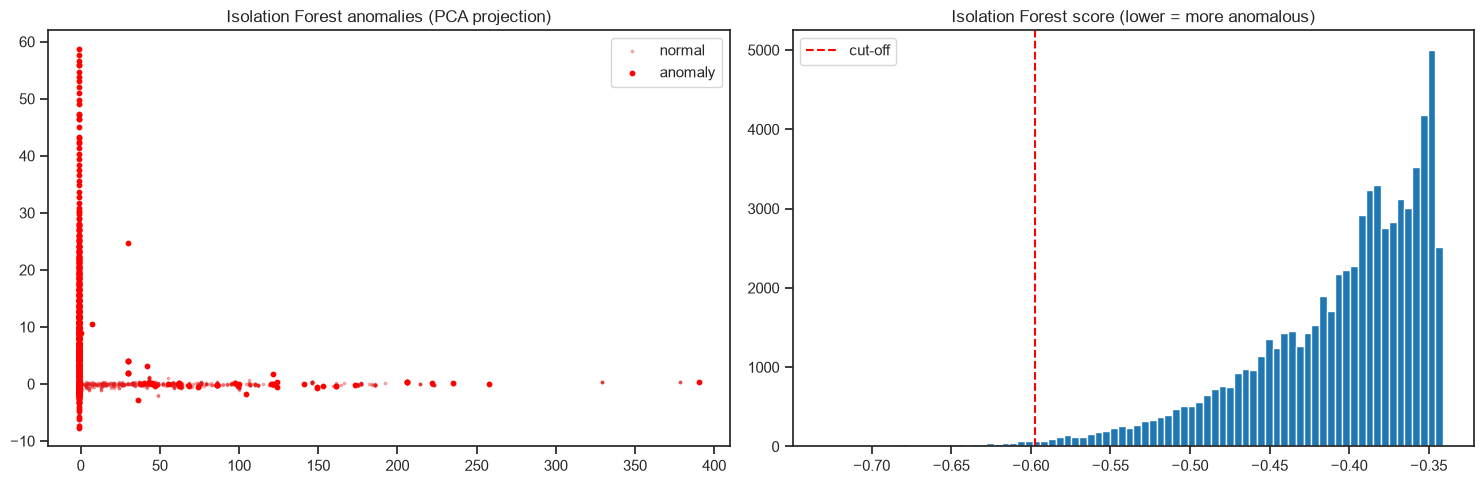

is_anomaly,normal (median),anomaly (median)
lead_time_log,3.7612,1.791759
total_nights,3.0000,2.000000
adr_per_person,47.0000,56.250000
total_guests,2.0000,1.000000
total_of_special_requests,0.0000,1.000000
booking_changes,0.0000,0.000000
days_in_waiting_list,0.0000,0.000000
previous_cancellations,0.0000,1.000000
previous_bookings_not_canceled,0.0000,6.000000
is_canceled,0.0000,0.000000


Cancel rate normal vs anomaly: {0: 0.258, 1: 0.148}


In [35]:
CONTAMINATION = 0.01
anom_scaler = RobustScaler().fit(train_df[ANOM_FEATS])
iso = IsolationForest(n_estimators=300, contamination=CONTAMINATION, random_state=RANDOM_STATE, n_jobs=-1)
X_anom = anom_scaler.transform(train_df[ANOM_FEATS])
train_df["is_anomaly"] = (iso.fit_predict(X_anom) == -1).astype(int)

pca_vis = PCA(n_components=2, random_state=RANDOM_STATE).fit(X_anom)
P = pca_vis.transform(X_anom)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].scatter(P[train_df["is_anomaly"] == 0, 0], P[train_df["is_anomaly"] == 0, 1], s=3, alpha=.3, label="normal")
axes[0].scatter(P[train_df["is_anomaly"] == 1, 0], P[train_df["is_anomaly"] == 1, 1], s=10, c="red", label="anomaly")
axes[0].set_title("Isolation Forest anomalies (PCA projection)")
axes[0].legend()
axes[1].hist(iso.score_samples(X_anom), bins=80, color="tab:blue")
axes[1].axvline(np.quantile(iso.score_samples(X_anom), CONTAMINATION), color="red", ls="--", label="cut-off")
axes[1].set_title("Isolation Forest score (lower = more anomalous)")
axes[1].legend()
plt.tight_layout()
plt.show()

display(train_df.groupby("is_anomaly")[ANOM_FEATS + [TARGET]].median().T.rename(columns={0: "normal (median)", 1: "anomaly (median)"}))
print("Cancel rate normal vs anomaly:", train_df.groupby("is_anomaly")[TARGET].mean().round(3).to_dict())

In [36]:
n = len(train_df)
train_df = train_df[train_df["is_anomaly"] == 0].drop(columns="is_anomaly")
print(f"Removed {n - len(train_df)} anomalous training rows ({(n - len(train_df)) / n:.1%}). The test set is left untouched so it still reflects real data.")

Removed 697 anomalous training rows (1.0%). The test set is left untouched so it still reflects real data.


> ✍️ **Your observations (anomalies):** what do the anomalous bookings look like (very long stays, huge parties, long waiting lists)? Are they errors or rare but real?

## 11. Clustering: guest segments
K-Means on standardised **continuous** booking-behaviour features (the target is **not** used). Binary flags such as `is_family` or `is_repeated_guest` are left out on purpose: after scaling they dominate the Euclidean distance, and K-Means would just split on them. *k* is chosen with the elbow curve and the silhouette score (computed on a 5k sample for speed). The segment label then becomes a new feature, and its cancellation rate is profiled.

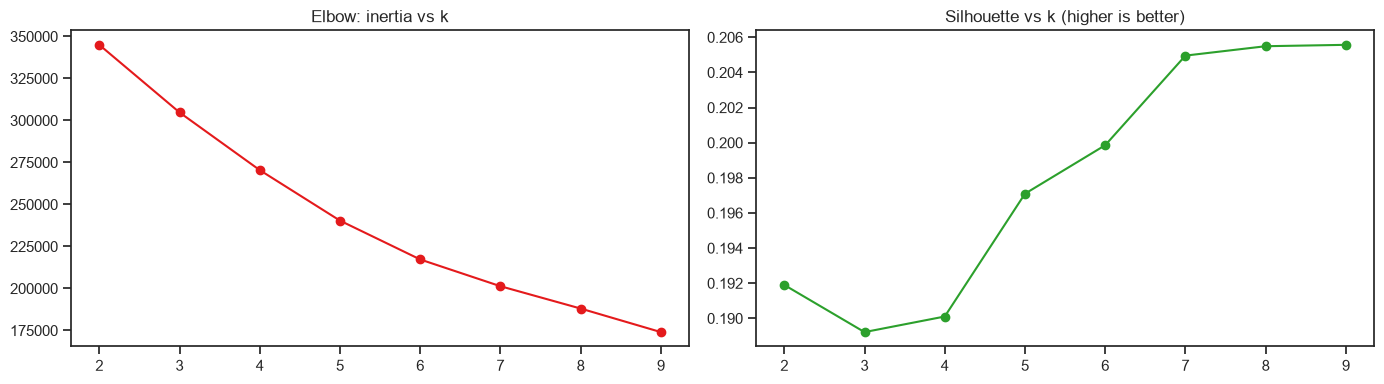

Chosen k = 9


In [37]:
CLUSTER_FEATS = ["lead_time_log", "total_nights", "weekend_share", "adr_per_person", "total_guests",
                 "total_of_special_requests"]
clu_scaler = StandardScaler().fit(train_df[CLUSTER_FEATS])
Xc = clu_scaler.transform(train_df[CLUSTER_FEATS])
sil_idx = np.random.default_rng(RANDOM_STATE).choice(len(Xc), size=min(5000, len(Xc)), replace=False)

ks, inertias, sils = range(2, 10), [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=10, random_state=RANDOM_STATE).fit(Xc)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(Xc[sil_idx], km.labels_[sil_idx]))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(list(ks), inertias, marker="o")
axes[0].set_title("Elbow: inertia vs k")
axes[1].plot(list(ks), sils, marker="o", color="tab:green")
axes[1].set_title("Silhouette vs k (higher is better)")
plt.tight_layout()
plt.show()

K_OVERRIDE = None   # set an int here if the elbow suggests a better k than the silhouette maximum
BEST_K = K_OVERRIDE or list(ks)[int(np.argmax(sils))]
print("Chosen k =", BEST_K)

,lead_time_log,total_nights,weekend_share,adr_per_person,total_guests,total_of_special_requests,is_family,is_repeated_guest,lead_time,size,cancel_rate
guest_segment,,,,,,,,,,,
seg_0,3.87,3.76,0.25,49.30,2.23,2.22,0.15,0.02,80.60,8652,0.21
seg_1,4.27,4.64,0.37,45.58,1.91,0.40,0.01,0.00,101.17,18384,0.30
seg_2,0.92,1.77,0.06,42.38,1.70,0.40,0.03,0.14,2.58,10129,0.08
seg_3,2.29,1.66,0.90,53.04,1.82,0.52,0.05,0.06,27.62,5702,0.19
seg_4,4.18,2.39,0.00,46.36,1.90,0.40,0.01,0.01,94.36,10486,0.34
seg_5,2.84,2.79,0.18,109.30,1.23,0.46,0.00,0.04,40.42,6366,0.25
seg_6,4.55,12.53,0.29,46.81,1.99,0.57,0.06,0.01,135.62,2522,0.31
seg_7,3.87,3.77,0.25,43.63,3.40,0.52,0.64,0.00,78.82,6736,0.38
seg_8,5.83,5.42,0.32,0.00,30.75,0.00,0.00,0.00,339.67,12,1.00


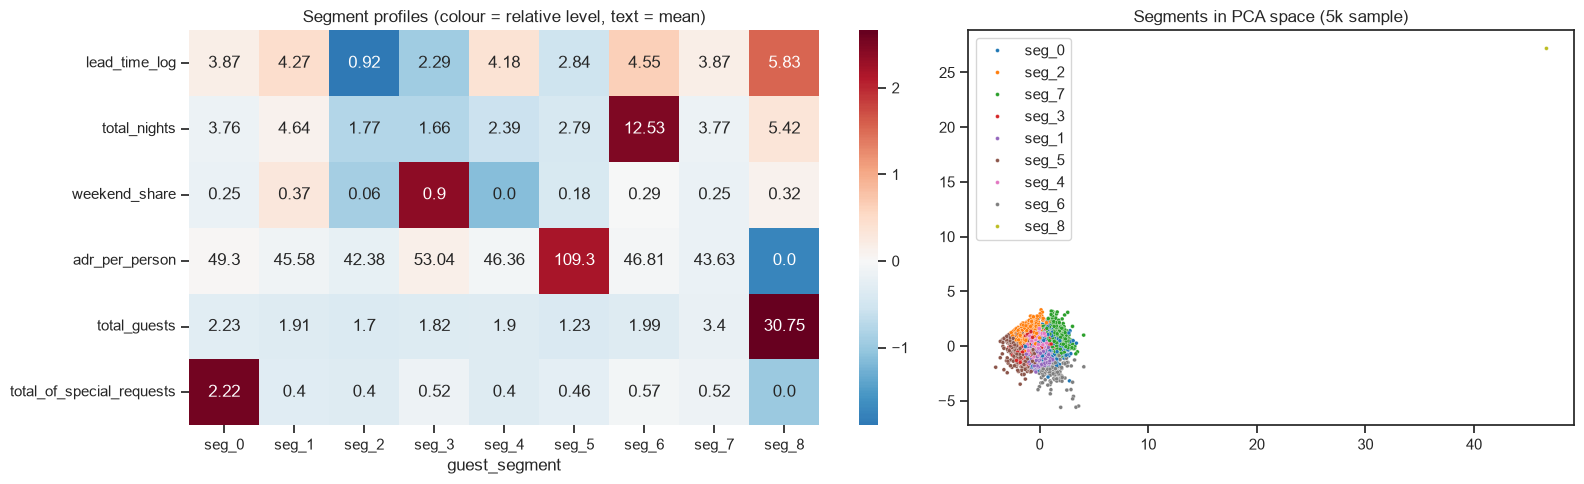

In [38]:
kmeans = KMeans(n_clusters=BEST_K, n_init=10, random_state=RANDOM_STATE).fit(Xc)
train_df["guest_segment"] = [f"seg_{c}" for c in kmeans.labels_]
test_df["guest_segment"] = [f"seg_{c}" for c in kmeans.predict(clu_scaler.transform(test_df[CLUSTER_FEATS]))]

profile = train_df.groupby("guest_segment")[CLUSTER_FEATS + ["is_family", "is_repeated_guest", "lead_time"]].mean()
profile["size"] = train_df["guest_segment"].value_counts()
profile["cancel_rate"] = train_df.groupby("guest_segment")[TARGET].mean()
display(profile.round(2))

fig, axes = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1.3, 1]})
z = (profile[CLUSTER_FEATS] - profile[CLUSTER_FEATS].mean()) / profile[CLUSTER_FEATS].std()
sns.heatmap(z.T, cmap="RdBu_r", center=0, annot=profile[CLUSTER_FEATS].T.round(2), fmt="", ax=axes[0])
axes[0].set_title("Segment profiles (colour = relative level, text = mean)")
P2 = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(Xc[sil_idx])
sns.scatterplot(x=P2[:, 0], y=P2[:, 1], hue=train_df["guest_segment"].values[sil_idx], s=8, ax=axes[1], palette="tab10")
axes[1].set_title("Segments in PCA space (5k sample)")
plt.tight_layout()
plt.show()

> ✍️ **Your observations (segments):** name each segment (e.g. "last-minute business singles", "long-lead families") and compare their cancellation rates.

## 12. Feature selection
Three filters, all computed on train:
1. **Quasi-constant**: features where one value covers ≥ 99% of rows carry almost no information.
2. **Redundant**: for numeric pairs with |Spearman ρ| > 0.9, drop the one with lower mutual information (MI) with the target.
3. **Uninformative**: features whose MI with the target is no better than **random noise**. Three random *probe* columns (continuous, binary and 10-level categorical) are added, and any real feature scoring below the best probe is dropped. This avoids picking an arbitrary MI threshold.

AutoViML runs its own selection on top of this (SULOV, which removes collinear variables, then recursive XGBoost), so this step is a first, explainable cut.

MI noise floor (best random probe): 0.00011
  |rho|=1.00: lead_time vs lead_time_log -> drop lead_time
  |rho|=1.00: arrival_date_week_number vs arrival_month_num -> drop arrival_date_week_number
  |rho|=0.95: children vs is_family -> drop children
  |rho|=1.00: previous_cancellations vs prev_cancel_ratio -> drop prev_cancel_ratio
  |rho|=0.95: total_of_special_requests vs has_special_requests -> drop total_of_special_requests

Quasi-constant: []
Redundant: ['arrival_date_week_number', 'children', 'lead_time', 'prev_cancel_ratio', 'total_of_special_requests']
Uninformative (MI ≤ noise floor): ['is_repeated_guest', 'arrival_dow', 'babies', 'arrival_date_day_of_month', 'arrival_date_week_number']

Kept 28 of 37 features


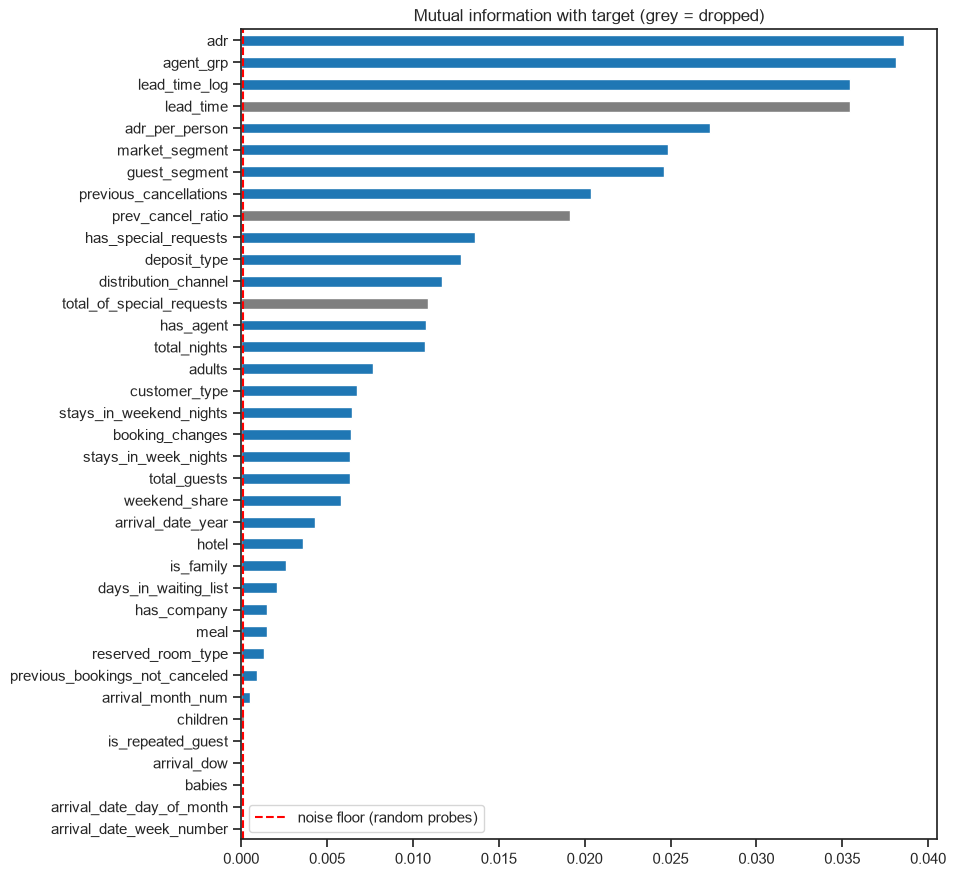

In [39]:
feat_cols = [c for c in train_df.columns if c != TARGET]
cat_cols = train_df[feat_cols].select_dtypes(include=["object", "category"]).columns.tolist()
num_cols = [c for c in feat_cols if c not in cat_cols]

# 1) quasi-constant
top_share = train_df[feat_cols].apply(lambda s: s.value_counts(normalize=True).iloc[0])
quasi_const = top_share[top_share >= 0.99].index.tolist()

# 3) mutual information (computed first because step 2 uses it)
mi_sample = train_df.sample(min(30000, len(train_df)), random_state=RANDOM_STATE)
X_mi = mi_sample[feat_cols].copy()
X_mi[cat_cols] = OrdinalEncoder().fit_transform(X_mi[cat_cols])
rng = np.random.default_rng(RANDOM_STATE)
PROBES = {"_probe_continuous": (rng.normal(size=len(X_mi)), False),
          "_probe_binary": (rng.integers(0, 2, len(X_mi)), True),
          "_probe_categorical": (rng.integers(0, 10, len(X_mi)), True)}
for p, (vals, _) in PROBES.items():
    X_mi[p] = vals
discrete = [c in cat_cols for c in feat_cols] + [d for _, d in PROBES.values()]
mi_all = pd.Series(mutual_info_classif(X_mi, mi_sample[TARGET], discrete_features=discrete,
                                       random_state=RANDOM_STATE), index=X_mi.columns).sort_values(ascending=False)
NOISE_FLOOR = mi_all[list(PROBES)].max()
mi = mi_all.drop(list(PROBES))
print(f"MI noise floor (best random probe): {NOISE_FLOOR:.5f}")

# 2) redundancy among numeric features
c = train_df[num_cols].corr(method="spearman").abs()
redundant = set()
for i, a in enumerate(num_cols):
    for b in num_cols[i + 1:]:
        if c.loc[a, b] > 0.9 and a not in redundant and b not in redundant:
            redundant.add(a if mi[a] < mi[b] else b)
            print(f"  |rho|={c.loc[a, b]:.2f}: {a} vs {b} -> drop {a if mi[a] < mi[b] else b}")

uninformative = mi[mi <= NOISE_FLOOR].index.tolist()
DROP = sorted(set(quasi_const) | redundant | set(uninformative))
selected_features = [f for f in feat_cols if f not in DROP]
print("\nQuasi-constant:", quasi_const)
print("Redundant:", sorted(redundant))
print("Uninformative (MI ≤ noise floor):", uninformative)
print(f"\nKept {len(selected_features)} of {len(feat_cols)} features")

ax = mi.plot.barh(figsize=(8, 10), color=["tab:gray" if f in DROP else "tab:blue" for f in mi.index])
ax.invert_yaxis()
ax.axvline(NOISE_FLOOR, color="red", ls="--", label="noise floor (random probes)")
ax.legend()
plt.title("Mutual information with target (grey = dropped)")
plt.show()

## 13. Modeling
### 13.1 Baselines (scikit-learn)
A majority-class dummy and a one-hot + logistic-regression pipeline. AutoViML has to beat these to be worth using.

In [40]:
X_train, y_train = train_df[selected_features], train_df[TARGET]
X_test, y_test = test_df[selected_features], test_df[TARGET]
sel_cat = [c for c in selected_features if c in cat_cols]
sel_num = [c for c in selected_features if c not in cat_cols]


def evaluate(name, y_true, y_pred, y_proba=None):
    y_pred = np.asarray(y_pred).astype(int)
    return {"model": name,
            "accuracy": accuracy_score(y_true, y_pred),
            "balanced_acc": balanced_accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall": recall_score(y_true, y_pred),
            "f1": f1_score(y_true, y_pred),
            "roc_auc": roc_auc_score(y_true, y_proba) if y_proba is not None else np.nan}


results, probas = [], {}
dummy = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
results.append(evaluate("Baseline: majority class", y_test, dummy.predict(X_test)))

logreg = Pipeline([
    ("prep", ColumnTransformer([("num", StandardScaler(), sel_num),
                                ("cat", OneHotEncoder(handle_unknown="ignore"), sel_cat)])),
    ("clf", LogisticRegression(max_iter=2000)),
]).fit(X_train, y_train)
probas["Baseline: logistic regression"] = logreg.predict_proba(X_test)[:, 1]
results.append(evaluate("Baseline: logistic regression", y_test, logreg.predict(X_test), probas["Baseline: logistic regression"]))
pd.DataFrame(results).set_index("model").round(4)

,accuracy,balanced_acc,precision,recall,f1,roc_auc
model,,,,,,
Baseline: majority class,0.6532,0.500,0.0000,0.0000,0.0000,NaN
Baseline: logistic regression,0.7339,0.677,0.6552,0.4913,0.5615,0.7685


### 13.2 AutoViML
`Auto_ViML` takes the train and test frames and handles the rest itself: encoding, feature reduction (SULOV + recursive XGBoost), randomized hyper-parameter search and model fitting. `Boosting_Flag` chooses the model family:

| `Boosting_Flag` | Main model |
|---|---|
| `None` | Linear (logistic regression) |
| `False` | Random Forest |
| `True` | XGBoost |
| `"CatBoost"` | CatBoost |

Each run also trains a small **ensemble** of extra models (e.g. Decision Tree, Naive Bayes, Bagging, AdaBoost, LDA, Linear SVC) and reports their predictions too. Altogether that is **10+ different models**, all scored on the same held-out test set. The scoring metric is **balanced accuracy** because the classes are imbalanced, and the cancellation rate also drifts between the training and test periods (section 6).

*Runtime: a few minutes per configuration on the full data.*

Imported Auto_ViML version: 0.2.02. Call using:
             m, feats, trainm, testm = Auto_ViML(train, target, test,
                            sample_submission='',
                            scoring_parameter='', KMeans_Featurizer=False,
                            hyper_param='RS',feature_reduction=True,
                             Boosting_Flag='CatBoost', Binning_Flag=False,
                            Add_Poly=0, Stacking_Flag=False,Imbalanced_Flag=False,
                            GPU_flag=False, verbose=1)
            

Imported Auto_NLP version: 0.1.01.. Call using:
     train_nlp, test_nlp, nlp_pipeline, predictions = Auto_NLP(
                nlp_column, train, test, target, score_type='balanced_accuracy',
                modeltype='Classification',top_num_features=200, verbose=0,
                build_model=True)

============================== AutoViML: Linear (Boosting_Flag=None) ==============================
##############  D A T A   S E T  A N A L Y S I S  #######

    28 Predictors classified...
    1 variables removed since they were ID or low-information variables
##############################################################################
######     D A T A    P R E P A R A T I O N   AND C L E A N I N G     ########
##############################################################################
No Missing Values in train data set
    Test data has no missing values. Continuing...
    Completed Label Encoding and Filling of Missing Values for Train and Test Data
Binary_Classification problem: hyperparameters are being optimized for balanced_accuracy
Processing arrival_date_year column for date time features....


    Adding 1 columns from date-time column arrival_date_year in train
        Adding time series features for test data...


#######################################################################################
#####  SULOV:  Searching for Uncorrelated List Of Variables in 5 features ############
#######################################################################################
    there are no null values in dataset...


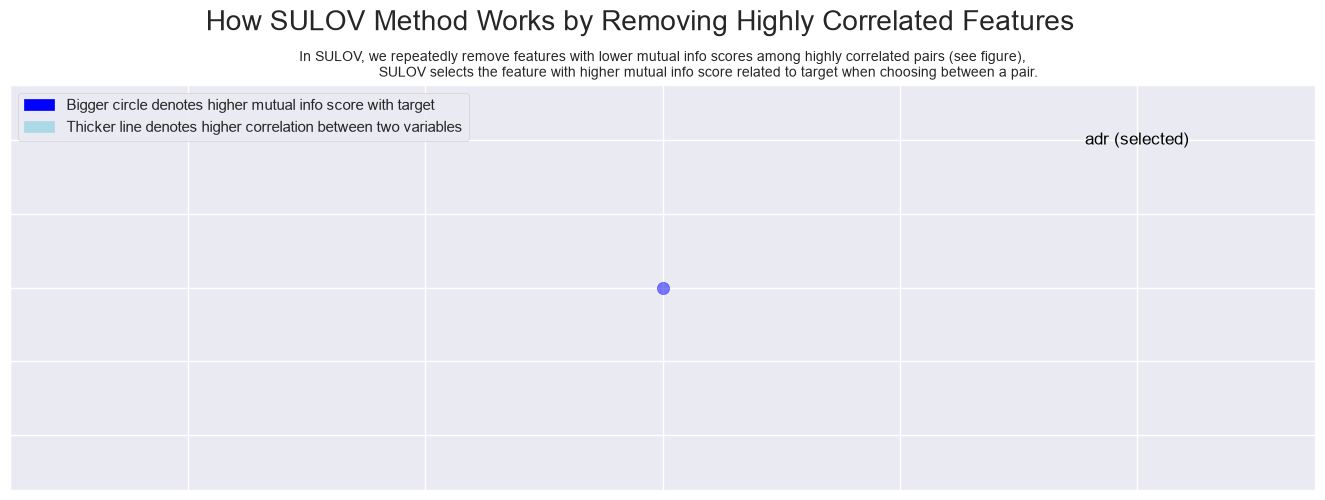

Splitting selected features into float and categorical (integer) variables:
    (5) float variables ...
    (24) categorical vars...
###############################################################################
#######     F E A T U R E   S E L E C T I O N    BY   X G B O O S T    ########
###############################################################################
Current number of predictors = 29 
    Finding Important Features using Boosted Trees algorithm...
        using 29 variables...


        using 23 variables...


        using 17 variables...


        using 11 variables...


        using 5 variables...


Found 18 important features
    Performing limited feature engineering for binning, add_poly and KMeans_Featurizer flags  ...
    Train CV Split completed with TRAIN rows =  55191 , CV rows =  13798
    Binning_Flag set to False or there are no float vars in data set to be binned
    KMeans_Featurizer set to False or there are no float variables in data
Performing MinMax scaling of train and validation data
#################################################################################
######## Linear    M O D E L   T R A I N I N G   ##########
#################################################################################
Rows in Train data set = 55191
  Features in Train data set = 18
    Rows in held-out data set = 13798
     Handling Imbalanced flag...
Finding Best Model and Hyper Parameters for Linear model...
    Baseline Accuracy Needed for Model = 74.17%
    CPU Count = 14 in this device
Using Linear Model, Estimated Training time = 1.42 mins


... (4 outputs left out)

###############  C O M P L E T E D  ################
Time Taken in mins = 0.4 for the Entire Process

============================== AutoViML: RandomForest (Boosting_Flag=False) ==============================
##############  D A T A   S E T  A N A L Y S I S  #######################
ALERT! Changing hyperparameter search to RS. Otherwise, Random Forests will take too long for 10,000+ rows
Training Set Shape = (68989, 29)
    Training Set Memory Usage = 15.26 MB
Test Set Shape = (17544, 28)
    Test Set Memory Usage = 3.75 MB
Single_Label Target: ['is_canceled']

################ Binary_Classification VISUALIZATION Started #####################
Random shuffling the data set before training
    Using RandomizedSearchCV for Hyper Parameter Tuning. This is 3X faster than GridSearchCV...
       Class  -> Counts -> Percent
           0:   51167  ->   74.2%
           1:   17822  ->   25.8%
    Target is_canceled is already numeric. No transformation done.
######################################

    28 Predictors classified...
    1 variables removed since they were ID or low-information variables
##############################################################################
######     D A T A    P R E P A R A T I O N   AND C L E A N I N G     ########
##############################################################################
No Missing Values in train data set
    Test data has no missing values. Continuing...
    Completed Label Encoding and Filling of Missing Values for Train and Test Data
Binary_Classification problem: hyperparameters are being optimized for balanced_accuracy
Processing arrival_date_year column for date time features....


    Adding 1 columns from date-time column arrival_date_year in train
        Adding time series features for test data...


#######################################################################################
#####  SULOV:  Searching for Uncorrelated List Of Variables in 5 features ############
#######################################################################################
    there are no null values in dataset...


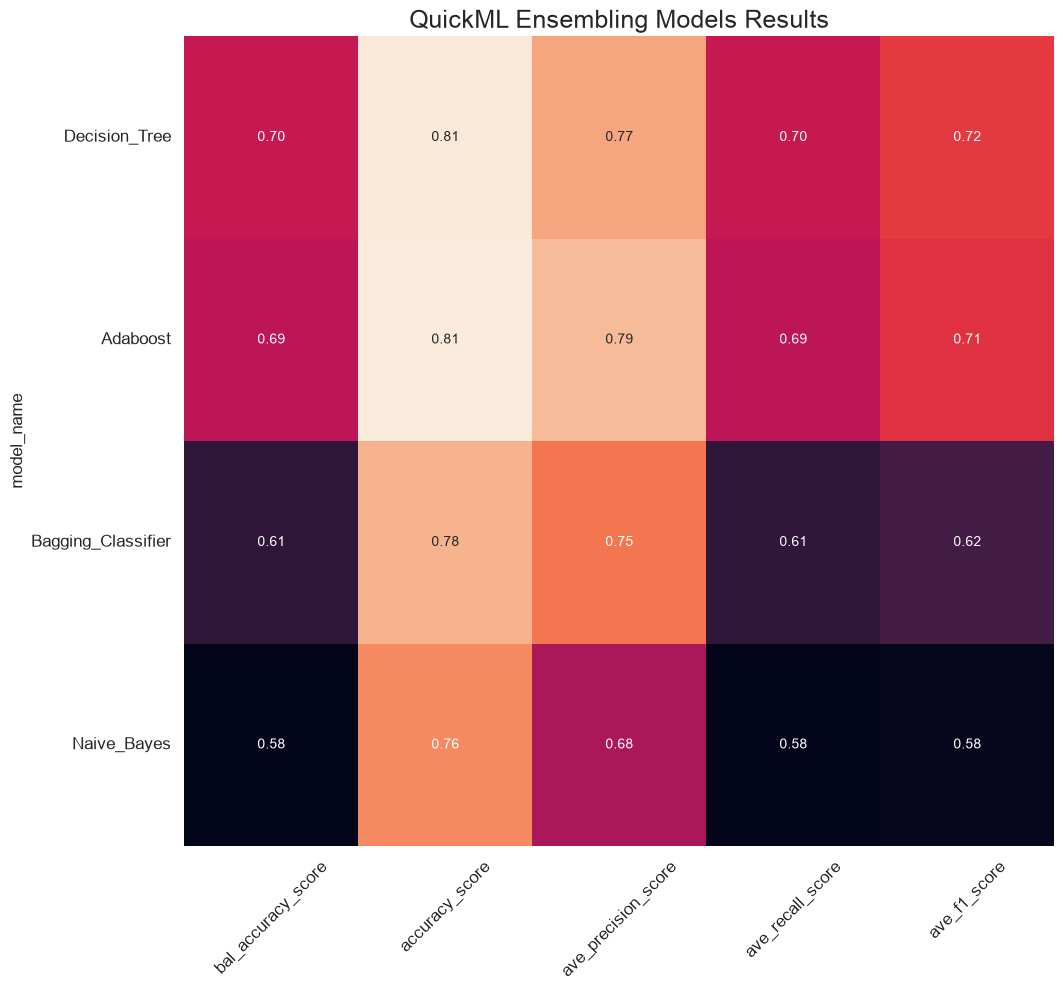

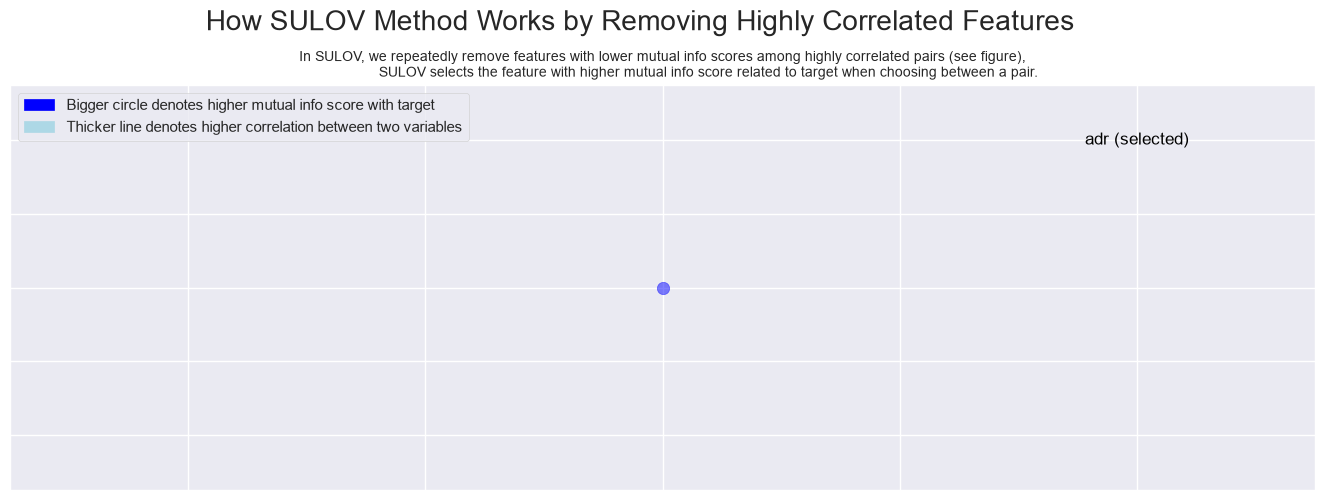

Splitting selected features into float and categorical (integer) variables:
    (5) float variables ...
    (24) categorical vars...


###############################################################################
#######     F E A T U R E   S E L E C T I O N    BY   X G B O O S T    ########
###############################################################################
Current number of predictors = 29 
    Finding Important Features using Boosted Trees algorithm...
        using 29 variables...


        using 23 variables...


        using 17 variables...


        using 11 variables...


        using 5 variables...


... (5 outputs left out)

###############  C O M P L E T E D  ################
Time Taken in mins = 2.2 for the Entire Process

============================== AutoViML: XGBoost (Boosting_Flag=True) ==============================
##############  D A T A   S E T  A N A L Y S I S  #######################
ALERT! Changing hyperparameter search to RS. Otherwise XGBoost will take too long for 10,000+ rows.
Training Set Shape = (68989, 29)
    Training Set Memory Usage = 15.26 MB
Test Set Shape = (17544, 28)
    Test Set Memory Usage = 3.75 MB
Single_Label Target: ['is_canceled']

################ Binary_Classification VISUALIZATION Started #####################
Random shuffling the data set before training
    Using RandomizedSearchCV for Hyper Parameter Tuning. This is 3X faster than GridSearchCV...
       Class  -> Counts -> Percent
           0:   51167  ->   74.2%
           1:   17822  ->   25.8%
    Target is_canceled is already numeric. No transformation done.
###################################################

    28 Predictors classified...
    1 variables removed since they were ID or low-information variables
##############################################################################
######     D A T A    P R E P A R A T I O N   AND C L E A N I N G     ########
##############################################################################
No Missing Values in train data set
    Test data has no missing values. Continuing...
    Completed Label Encoding and Filling of Missing Values for Train and Test Data
Binary_Classification problem: hyperparameters are being optimized for balanced_accuracy
Processing arrival_date_year column for date time features....


    Adding 1 columns from date-time column arrival_date_year in train
        Adding time series features for test data...


#######################################################################################
#####  SULOV:  Searching for Uncorrelated List Of Variables in 5 features ############
#######################################################################################
    there are no null values in dataset...


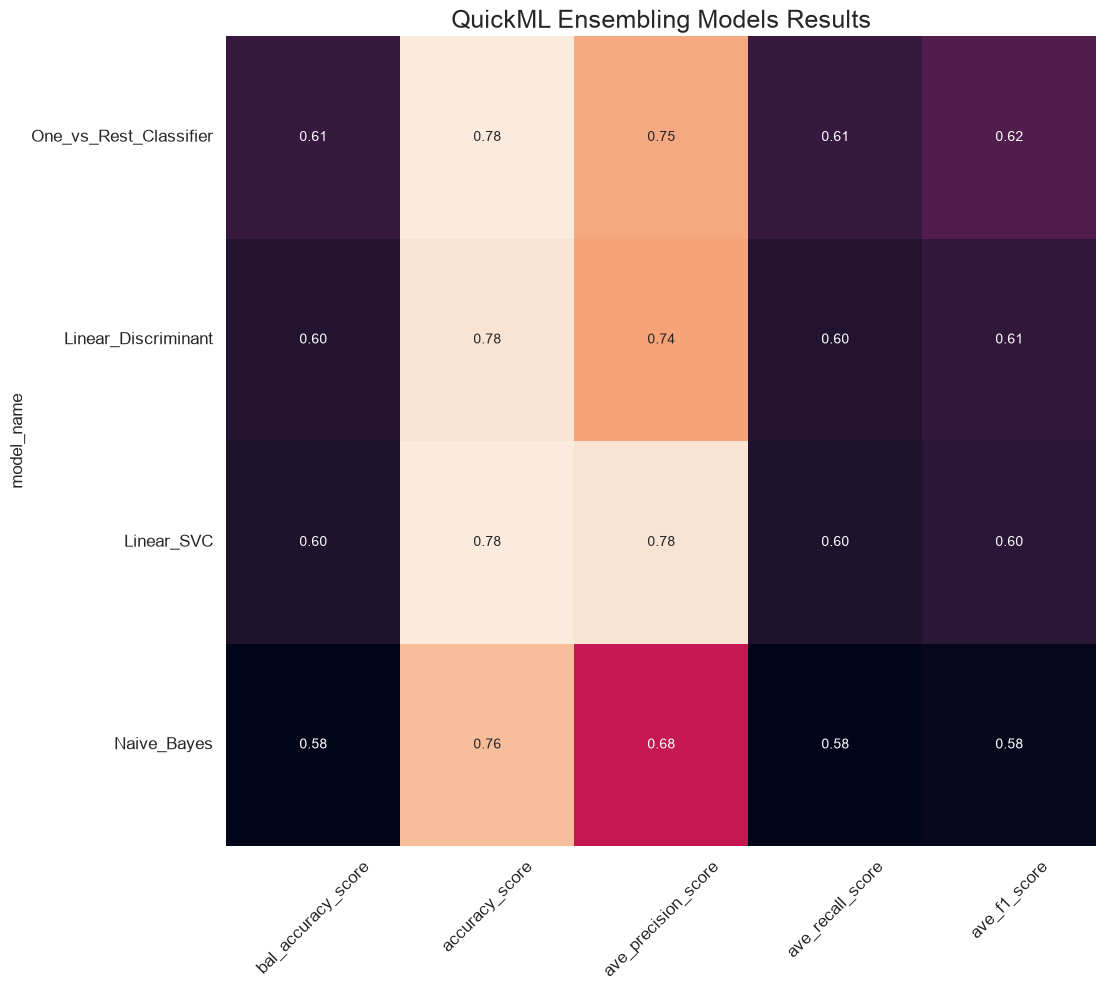

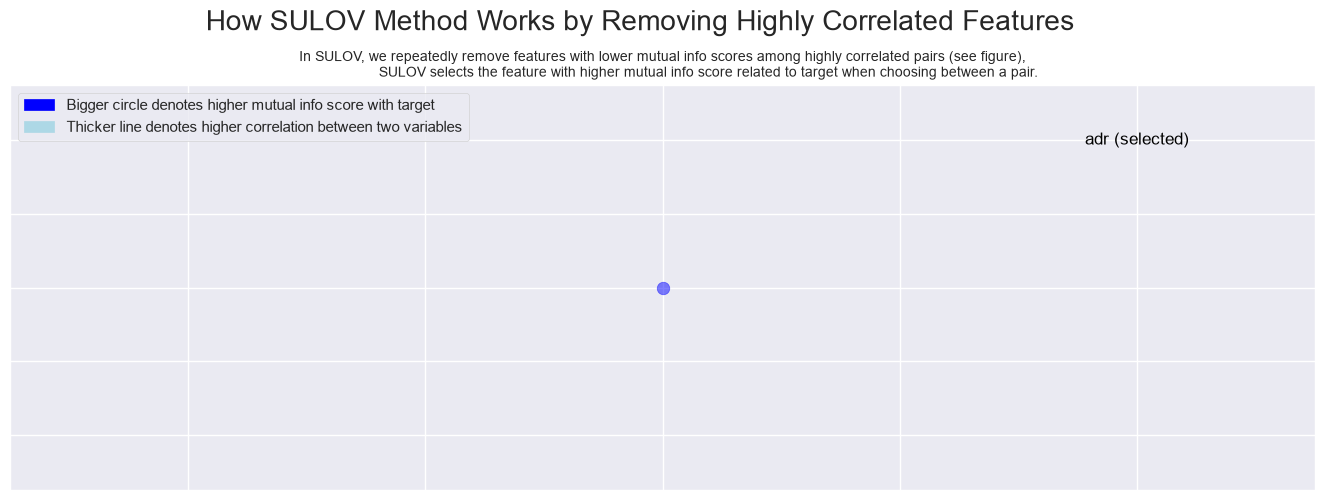

Splitting selected features into float and categorical (integer) variables:
    (5) float variables ...
    (24) categorical vars...
###############################################################################
#######     F E A T U R E   S E L E C T I O N    BY   X G B O O S T    ########
###############################################################################
Current number of predictors = 29 
    Finding Important Features using Boosted Trees algorithm...
        using 29 variables...


        using 23 variables...


        using 17 variables...


        using 11 variables...


        using 5 variables...


Found 18 important features
    Performing limited feature engineering for binning, add_poly and KMeans_Featurizer flags  ...
    Train CV Split completed with TRAIN rows =  55191 , CV rows =  13798
    Binning_Flag set to False or there are no float vars in data set to be binned
    KMeans_Featurizer set to False or there are no float variables in data
Performing MinMax scaling of train and validation data
#################################################################################
######## XGBoost    M O D E L   T R A I N I N G   ##########
#################################################################################
Rows in Train data set = 55191
  Features in Train data set = 18
    Rows in held-out data set = 13798
     Handling Imbalanced flag...
Finding Best Model and Hyper Parameters for XGBoost model...
    Baseline Accuracy Needed for Model = 74.17%
    CPU Count = 14 in this device
Using XGBoost Model, Estimated Training time = 3.55 mins


... (5 outputs left out)

Training Set Shape = (68989, 29)
    Training Set Memory Usage = 15.26 MB
Test Set Shape = (17544, 28)
    Test Set Memory Usage = 3.75 MB
Single_Label Target: ['is_canceled']

################ Binary_Classification VISUALIZATION Started #####################
Random shuffling the data set before training
    Using RandomizedSearchCV for Hyper Parameter Tuning. This is 3X faster than GridSearchCV...
       Class  -> Counts -> Percent
           0:   51167  ->   74.2%
           1:   17822  ->   25.8%
    Target is_canceled is already numeric. No transformation done.
#######################################################################################
######################## C L A S S I F Y I N G  V A R I A B L E S  ####################
#######################################################################################
Classifying variables in data set...


    28 Predictors classified...
    1 variables removed since they were ID or low-information variables
##############################################################################
######     D A T A    P R E P A R A T I O N   AND C L E A N I N G     ########
##############################################################################
No Missing Values in train data set
    Test data has no missing values. Continuing...
    Completed Label Encoding and Filling of Missing Values for Train and Test Data
Binary_Classification problem: hyperparameters are being optimized for balanced_accuracy
Processing arrival_date_year column for date time features....


    Adding 1 columns from date-time column arrival_date_year in train
        Adding time series features for test data...


#######################################################################################
#####  SULOV:  Searching for Uncorrelated List Of Variables in 5 features ############
#######################################################################################
    there are no null values in dataset...


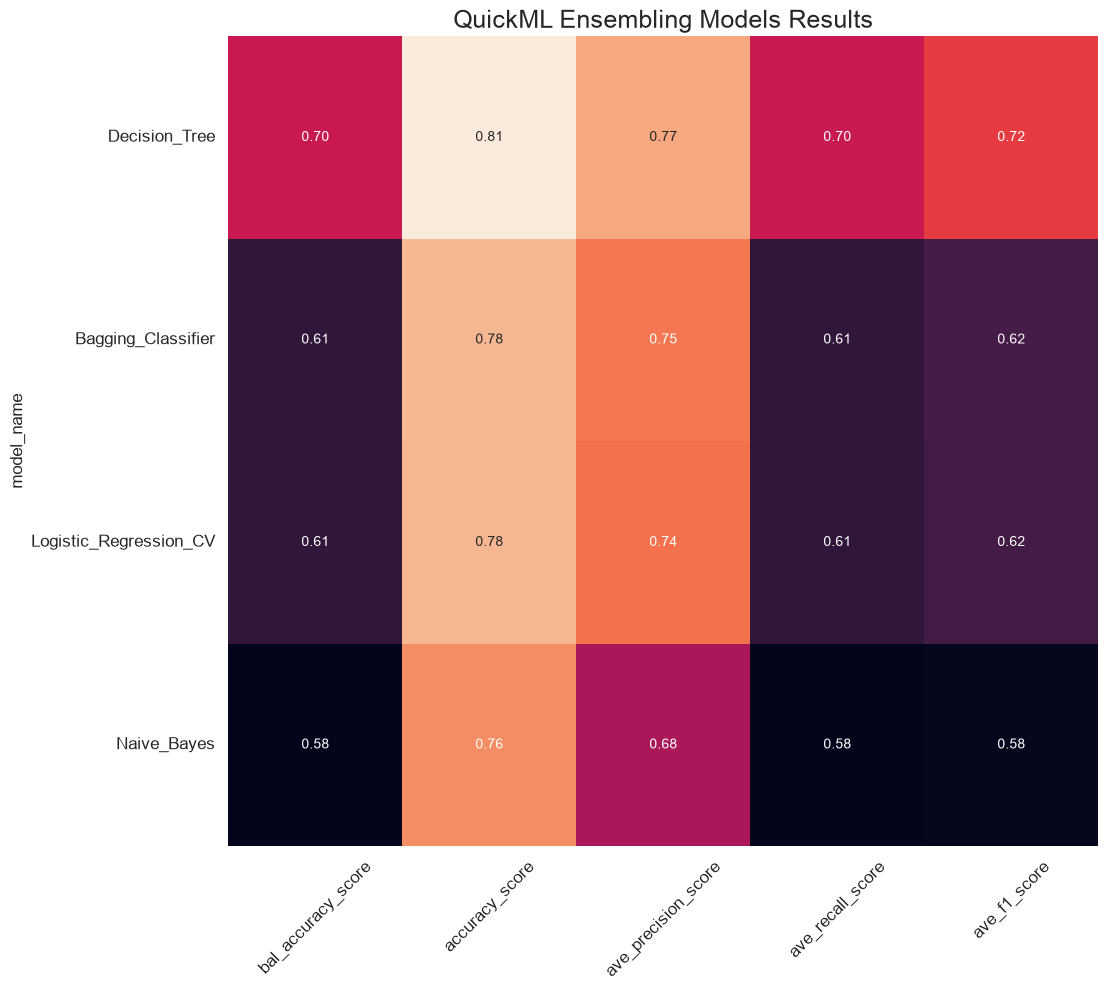

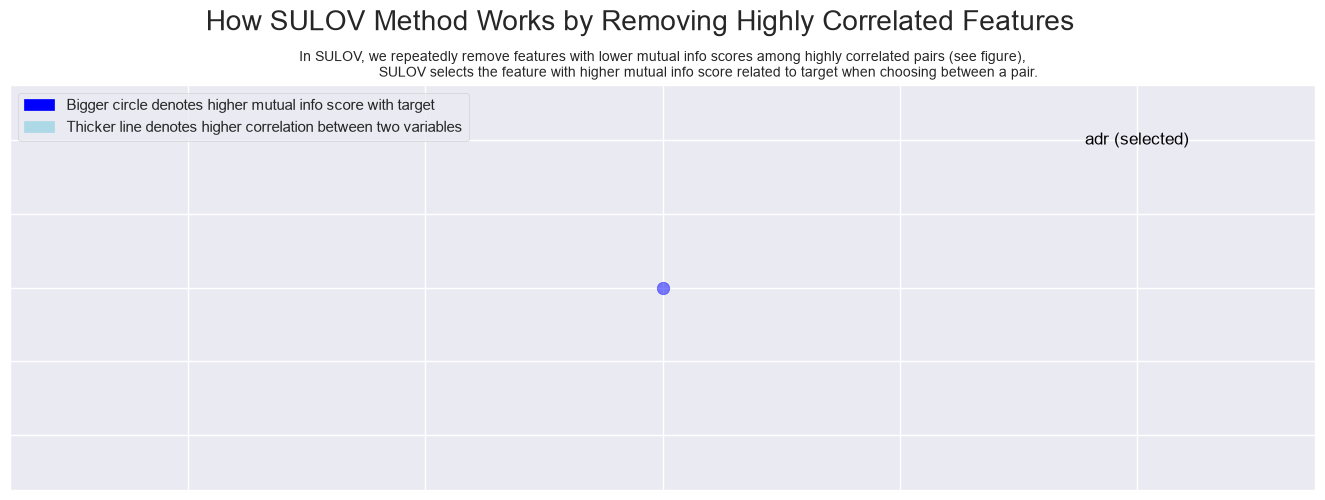

Splitting selected features into float and categorical (integer) variables:
    (5) float variables ...
    (24) categorical vars...


###############################################################################
#######     F E A T U R E   S E L E C T I O N    BY   X G B O O S T    ########
###############################################################################
Current number of predictors = 29 
    Finding Important Features using Boosted Trees algorithm...
        using 29 variables...


        using 23 variables...


        using 17 variables...


        using 11 variables...


        using 5 variables...


... (3 outputs left out)

Time taken = 1 seconds
Based on trying multiple models, Best type of algorithm for this data set is Decision_Tree
#############################################################################
    Displaying results of weighted average ensemble of 5 classifiers
After multiple models, Ensemble Model Results:
Binary Class Model Metrics Report
#####################################################
    Accuracy          = 81.9%
    Balanced Accuracy = 71.2%
    Precision         = 72.0%
    Average Precision = 78.0%
    Recall            = 49.0%
    F1 Score          = 58.3%
#####################################################
              precision    recall  f1-score   support

           0       0.84      0.93      0.88     10234
           1       0.72      0.49      0.58      3564

    accuracy                           0.82     13798
   macro avg       0.78      0.71      0.73     13798
weighted avg       0.81      0.82      0.81     13798

[[9555  679]
 [1819 1745]]
################

     Actual Training time taken in seconds = 6
Training of models completed. Now starting predictions on test data...
    Making test Data predictions using modified Threshold = 0.299


    Calculating weighted average ensemble of 5 classifiers
    Plotting Feature Importances to explain the output of model
############### P R E D I C T I O N  O N  T E S T   C O M P L E T E D  #################
    Time taken thus far (in seconds) = 28
Writing Output files to disk...
    Saving predictions to ./is_canceled/is_canceled_Binary_Classification_test_modified.csv
    Saving predictions to ./is_canceled/is_canceled_Binary_Classification_submission.csv
    Saving predictions to ./is_canceled/is_canceled_Binary_Classification_train_modified.csv


###############  C O M P L E T E D  ################
Time Taken in mins = 0.5 for the Entire Process


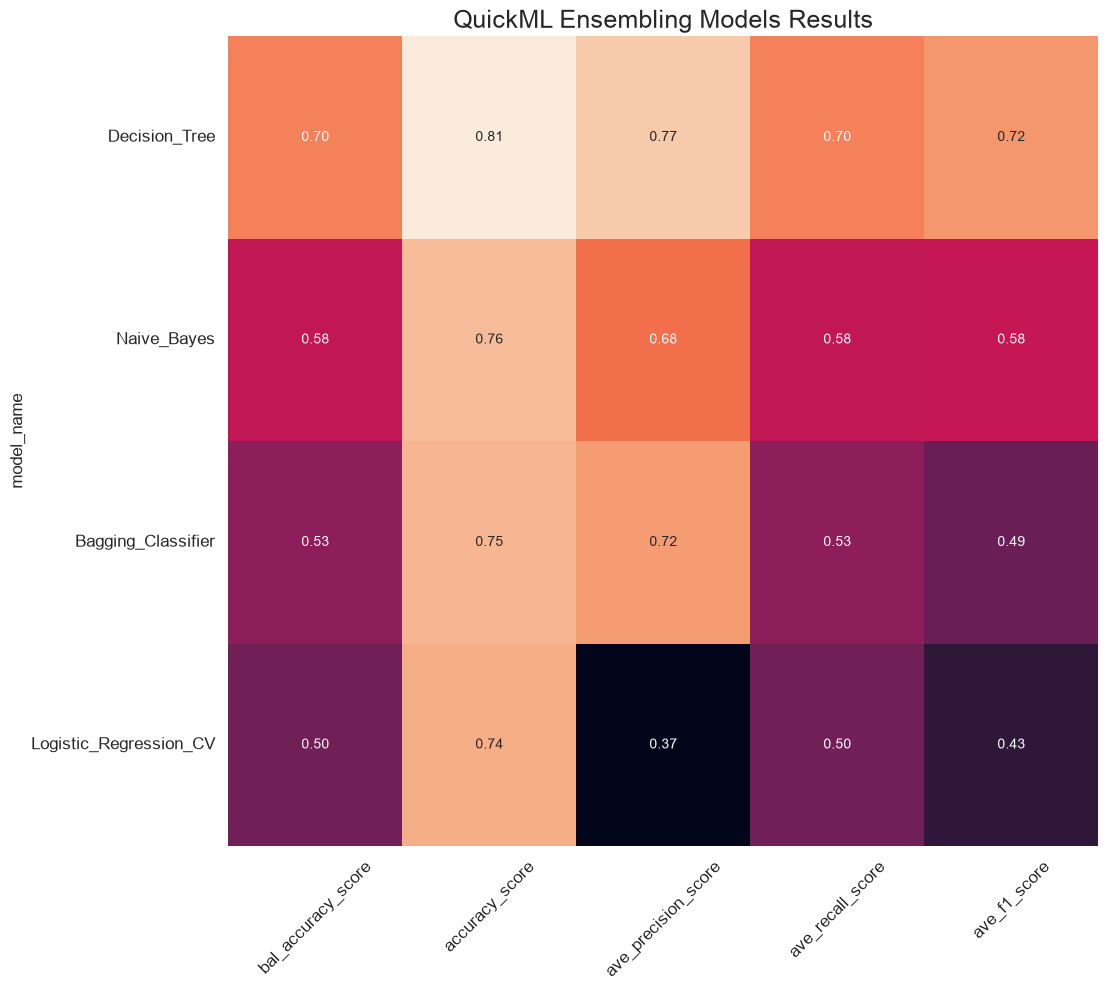

In [41]:
from autoviml.Auto_ViML import Auto_ViML

AVML_CONFIGS = {"Linear": None, "RandomForest": False, "XGBoost": True, "CatBoost": "CatBoost"}
avml_train = train_df[selected_features + [TARGET]].reset_index(drop=True)
avml_test = test_df[selected_features].reset_index(drop=True)
y_test_r = y_test.reset_index(drop=True)
avml_runs, seen_sub = {}, set()

for name, flag in AVML_CONFIGS.items():
    print(f"\n{'=' * 30} AutoViML: {name} (Boosting_Flag={flag!r}) {'=' * 30}")
    model, feats, trainm, testm = Auto_ViML(
        avml_train.copy(), TARGET, avml_test.copy(), sample_submission="",
        hyper_param="RS", feature_reduction=True, scoring_parameter="balanced_accuracy",
        Boosting_Flag=flag, KMeans_Featurizer=False, Binning_Flag=False, Add_Poly=0,
        Stacking_Flag=False, Imbalanced_Flag=False, verbose=0)
    avml_runs[name] = {"model": model, "features": feats, "testm": testm}
    probas[f"AutoViML {name}"] = testm[f"{TARGET}_proba_1"].values
    results.append(evaluate(f"AutoViML {name}", y_test_r, testm[f"{TARGET}_predictions"], testm[f"{TARGET}_proba_1"]))
    main_pred = testm[f"{TARGET}_predictions"]
    for col in testm.columns:   # the extra ensemble members AutoViML trained in this run
        if col.endswith("_predictions") and col != f"{TARGET}_predictions" and not testm[col].equals(main_pred):
            sub = col[len(TARGET) + 1:-len("_predictions")]
            label = f"AutoViML {name} → Ensemble" if sub == "Ensembled" else f"AutoViML ensemble member: {sub}"
            if label not in seen_sub:
                seen_sub.add(label)
                results.append(evaluate(label, y_test_r, testm[col]))

## 14. Results

,accuracy,balanced_acc,precision,recall,f1,roc_auc
model,,,,,,
AutoViML CatBoost,0.6914,0.7021,0.5404,0.7370,0.6236,0.7766
AutoViML XGBoost,0.6912,0.7020,0.5401,0.7372,0.6234,0.7769
AutoViML RandomForest,0.6688,0.6880,0.5155,0.7505,0.6112,0.7549
Baseline: logistic regression,0.7339,0.6770,0.6552,0.4913,0.5615,0.7685
AutoViML CatBoost → Ensemble,0.7272,0.6750,0.6340,0.5048,0.5620,nan
AutoViML XGBoost → Ensemble,0.7218,0.6636,0.6320,0.4737,0.5415,nan
AutoViML RandomForest → Ensemble,0.7130,0.6521,0.6172,0.4535,0.5228,nan
AutoViML ensemble member: Adaboost,0.7274,0.6518,0.6794,0.4052,0.5076,nan
AutoViML Linear → Ensemble,0.6904,0.6510,0.5573,0.5222,0.5392,nan


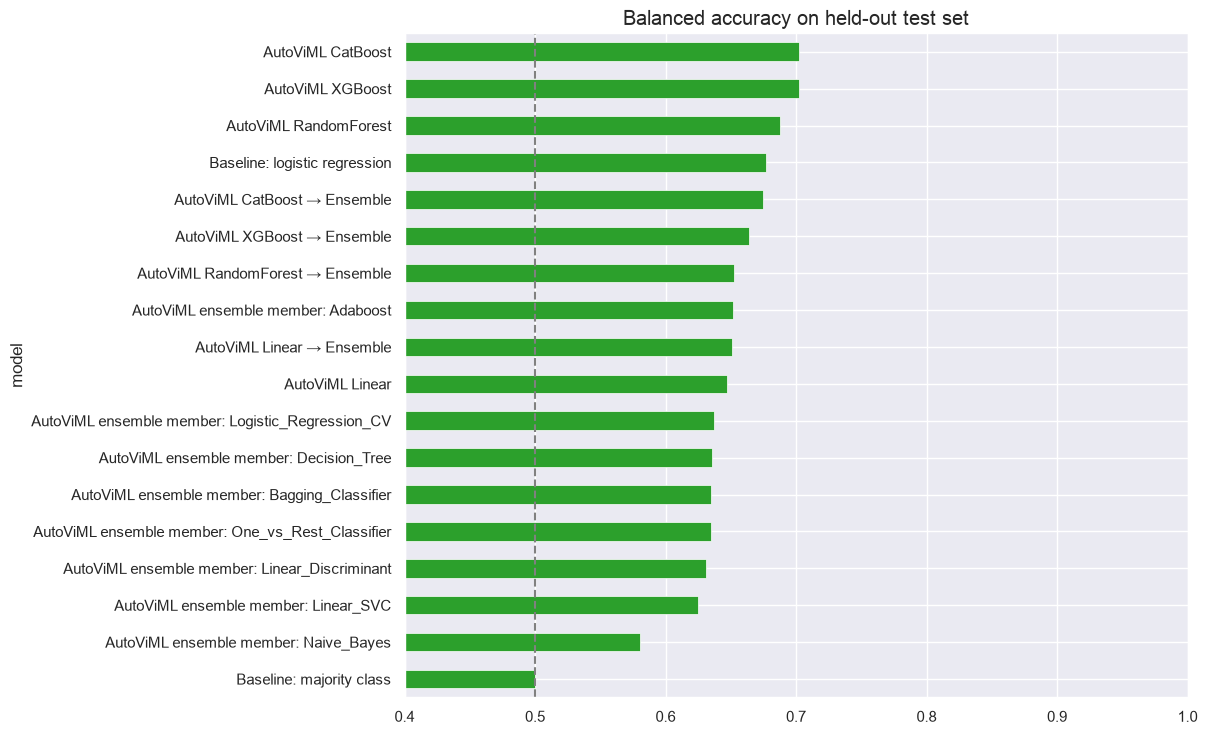

In [42]:
res = pd.DataFrame(results).set_index("model").sort_values("balanced_acc", ascending=False)
display(res.style.format("{:.4f}").background_gradient(cmap="Greens", subset=["balanced_acc", "f1", "roc_auc"]))

res["balanced_acc"].sort_values().plot.barh(figsize=(9, 0.4 * len(res) + 1), color="tab:green")
plt.axvline(0.5, ls="--", color="grey")
plt.title("Balanced accuracy on held-out test set")
plt.xlim(0.4, 1)
plt.show()

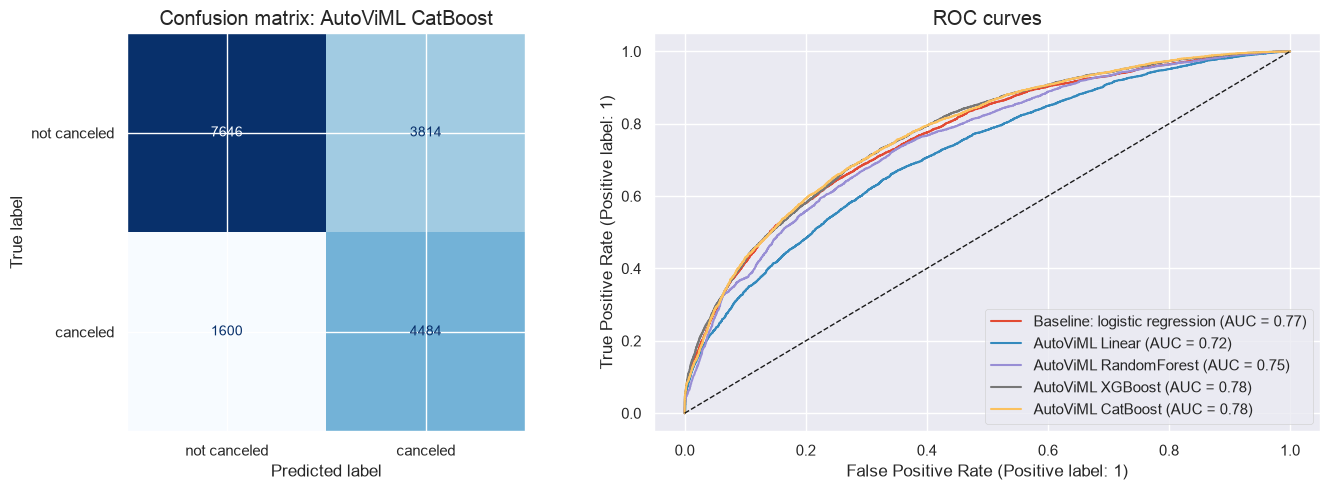

In [43]:
best_name = res.filter(like="AutoViML", axis=0).dropna(subset=["roc_auc"]).index[0]
best_run = avml_runs[best_name.replace("AutoViML ", "")]
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test_r, best_run["testm"][f"{TARGET}_predictions"].astype(int)),
                       display_labels=["not canceled", "canceled"]).plot(ax=axes[0], cmap="Blues", colorbar=False)
axes[0].set_title(f"Confusion matrix: {best_name}")
for name, p in probas.items():
    RocCurveDisplay.from_predictions(y_test_r, p, name=name, ax=axes[1])
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_title("ROC curves")
plt.tight_layout()
plt.show()

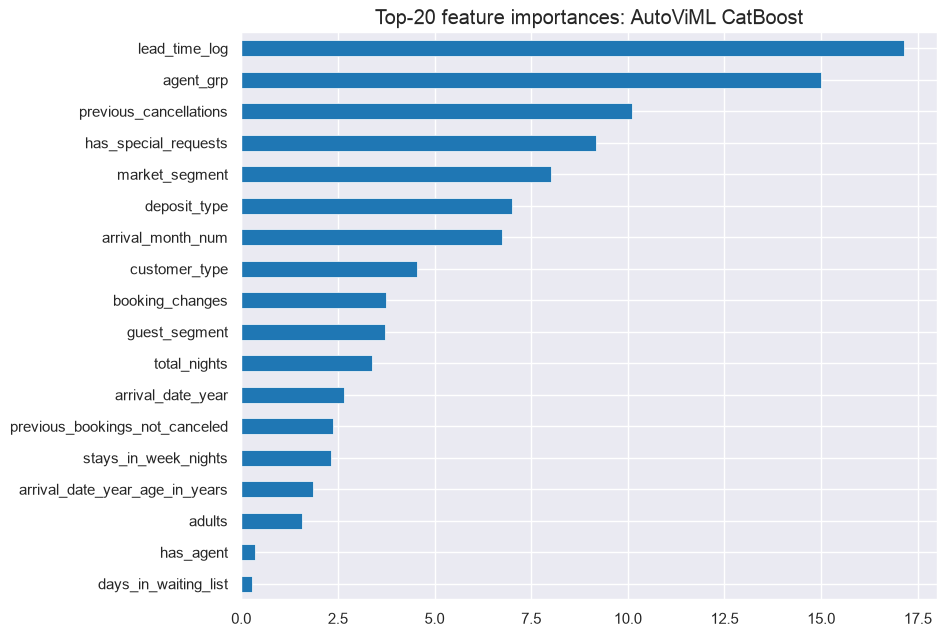

In [44]:
m = best_run["model"]
est = m.steps[-1][1] if hasattr(m, "steps") else m
if hasattr(est, "feature_importances_") and len(est.feature_importances_) == len(best_run["features"]):
    imp = pd.Series(est.feature_importances_, index=best_run["features"]).sort_values()
    imp.tail(20).plot.barh(figsize=(8, 7), color="tab:blue", title=f"Top-20 feature importances: {best_name}")
    plt.show()
else:
    print("Features AutoViML kept for", best_name, ":", best_run["features"])

## 15. Conclusions
> ✍️ **TODO (you), after running everything:**
> - **Data quality:** what you removed or fixed and why (duplicates, leakage, impossible rows, imputation choice).
> - **Key EDA insights:** the 3–5 strongest drivers of cancellation.
> - **Anomalies and segments:** what they revealed.
> - **Models:** which AutoViML configuration won, by how much it beat the baselines, and which features mattered most. Do those match your EDA?
> - **Honest evaluation:** what the chronological split, deduplication and leakage removal cost in score (section 7), and why the lower number is the one to trust.
> - **Limitations and next steps:** e.g. threshold tuning for the business cost of a missed cancellation, probability calibration, retraining cadence given the drift.